# DataCo Global Operations Analytics Using Chi-Square

# Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data Understanding

## Import Dataset dan Sumber, Nama, Format, serta Tujuan Dataset

In [2]:
data = pd.read_csv("DataCoSupplyChainDataset.csv", encoding="latin-1") # Membaca file csv

### Sumber, Nama, Format, dan Tujuan

In [3]:
df = pd.DataFrame(data) # Mengubahnya menjadi DataFrame

### Baris dan Kolom

In [4]:
pd.set_option("display.max_columns", None)
df

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.750000,0.29,1,327.750000,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.750000,-0.80,1,327.750000,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.750000,-0.80,1,327.750000,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.750000,0.08,1,327.750000,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.750000,0.45,1,327.750000,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/15/2018 11:24,Standard Class
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,EE. UU.,XXXXXXXXX,Maria,1005,Peterson,XXXXXXXXX,Home Office,NY,1322 Broad Glade,11207.0,7,Fan Shop,40.640930,-73.942711,Pacific Asia,Shanghái,China,1005,1/16/2016 3:40,26043,1004,0.000000,0.00,65177,399.980011,0.10,1,399.980011,399.980011,40.000000,Eastern Asia,Shanghái,CLOSED,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,S

### Deskripsi Kolom

In [5]:
from IPython.display import display, Markdown

# Membuat string tabel
markdown_table = """
| Nama Kolom | Deskripsi |
| :--- | :--- |
| **Type** | Jenis transaksi yang dilakukan |
| **Days for shipping (real)** | Lama pengiriman aktual dari produk yang dibeli |
| **Days for shipment (scheduled)** | Lama pengiriman terjadwal dari produk yang dibeli |
| **Benefit per order** | Keuntungan per pesanan yang ditempatkan |
| **Sales per customer** | Total penjualan per pelanggan |
| **Delivery Status** | Status pengiriman pesanan: Pengiriman lebih awal (Advance shipping), Pengiriman terlambat (Late delivery), Pengiriman dibatalkan (Shipping canceled), Pengiriman tepat waktu (Shipping on time) |
| **Late_delivery_risk** | Variabel kategorikal yang menunjukkan apakah pengiriman terlambat (1) atau tidak terlambat (0) |
| **Category Id** | Kode kategori produk |
| **Category Name** | Deskripsi kategori produk |
| **Customer City** | Kota tempat toko yang dipilih pelanggan melakukan pembelian |
| **Customer Country** | Negara tempat toko yang dipilih pelanggan melakukan pembelian |
| **Customer Email** | Email pelanggan |
| **Customer Fname** | Nama depan pelanggan |
| **Customer Id** | ID pelanggan |
| **Customer Lname** | Nama belakang pelanggan |
| **Customer Password** | Kunci pelanggan yang disamarkan (masked) |
| **Customer Segment** | Jenis pelanggan: Konsumen (Consumer), Perusahaan (Corporate), Kantor Rumah (Home Office) |
| **Customer State** | Negara bagian tempat toko asal pembelian terdaftar |
| **Customer Street** | Jalan tempat toko asal pembelian terdaftar |
| **Customer Zipcode** | Kode pos pelanggan |
| **Department Id** | Kode departemen toko |
| **Department Name** | Nama departemen toko |
| **Latitude** | Garis lintang (latitude) yang sesuai dengan lokasi toko |
| **Longitude** | Garis bujur (longitude) yang sesuai dengan lokasi toko |
| **Market** | Pasar tempat pesanan dikirimkan: Afrika, Eropa, LATAM, Asia Pasifik, USCA |
| **Order City** | Kota tujuan pesanan |
| **Order Country** | Negara tujuan pesanan |
| **Order Customer Id** | Kode pesanan pelanggan |
| **order date (DateOrders)** | Tanggal saat pesanan dibuat |
| **Order Id** | Kode pesanan |
| **Order Item Cardprod Id** | Kode produk yang dihasilkan melalui pembaca RFID |
| **Order Item Discount** | Nilai diskon item pesanan |
| **Order Item Discount Rate** | Persentase diskon item pesanan |
| **Order Item Id** | Kode item pesanan |
| **Order Item Product Price** | Harga produk tanpa diskon |
| **Order Item Profit Ratio** | Rasio keuntungan item pesanan |
| **Order Item Quantity** | Jumlah produk per pesanan |
| **Sales** | Nilai penjualan |
| **Order Item Total** | Jumlah total per pesanan |
| **Order Profit Per Order** | Keuntungan pesanan per pesanan |
| **Order Region** | Kawasan dunia tempat pesanan dikirimkan: Asia Tenggara, Asia Selatan, Oseania, Asia Timur, Asia Barat, Bagian Barat AS, Pusat AS, Afrika Barat, Afrika Tengah, Afrika Utara, Eropa Barat, Eropa Utara, Karibia, Amerika Selatan, Afrika Timur, Eropa Selatan, Bagian Timur AS, Kanada, Afrika Selatan, Asia Tengah, Eropa, Amerika Tengah, Eropa Timur, Bagian Selatan AS |
| **Order State** | Negara bagian dari kawasan tempat pesanan dikirimkan |
| **Order Status** | Status pesanan: SELESAI (COMPLETE), TERTUNDA (PENDING), DITUTUP (CLOSED), MENUNGGU PEMBAYARAN (PENDING_PAYMENT), DIBATALKAN (CANCELED), DIPROSES (PROCESSING), DUGAAN PENIPUAN (SUSPECTED_FRAUD), DITAHAN (ON_HOLD), TINJAUAN PEMBAYARAN (PAYMENT_REVIEW) |
| **Order Zipcode** | Kode pos tujuan pengiriman pesanan |
| **Product Card Id** | Kode produk |
| **Product Category Id** | Kode kategori produk |
| **Product Description** | Deskripsi produk |
| **Product Image** | Tautan kunjungan dan pembelian produk |
| **Product Name** | Nama produk |
| **Product Price** | Harga produk |
| **Product Status** | Status stok produk: Jika bernilai 1 berarti tidak tersedia, jika 0 berarti produk tersedia |
| **Shipping date (DateOrders)** | Tanggal dan waktu persis pengiriman |
| **Shipping Mode** | Metode pengiriman yang digunakan: Kelas Standar (Standard Class), Kelas Satu (First Class), Kelas Dua (Second Class), Hari yang Sama (Same Day) |
"""

# Menampilkan tabel
display(Markdown(markdown_table))


| Nama Kolom | Deskripsi |
| :--- | :--- |
| **Type** | Jenis transaksi yang dilakukan |
| **Days for shipping (real)** | Lama pengiriman aktual dari produk yang dibeli |
| **Days for shipment (scheduled)** | Lama pengiriman terjadwal dari produk yang dibeli |
| **Benefit per order** | Keuntungan per pesanan yang ditempatkan |
| **Sales per customer** | Total penjualan per pelanggan |
| **Delivery Status** | Status pengiriman pesanan: Pengiriman lebih awal (Advance shipping), Pengiriman terlambat (Late delivery), Pengiriman dibatalkan (Shipping canceled), Pengiriman tepat waktu (Shipping on time) |
| **Late_delivery_risk** | Variabel kategorikal yang menunjukkan apakah pengiriman terlambat (1) atau tidak terlambat (0) |
| **Category Id** | Kode kategori produk |
| **Category Name** | Deskripsi kategori produk |
| **Customer City** | Kota tempat toko yang dipilih pelanggan melakukan pembelian |
| **Customer Country** | Negara tempat toko yang dipilih pelanggan melakukan pembelian |
| **Customer Email** | Email pelanggan |
| **Customer Fname** | Nama depan pelanggan |
| **Customer Id** | ID pelanggan |
| **Customer Lname** | Nama belakang pelanggan |
| **Customer Password** | Kunci pelanggan yang disamarkan (masked) |
| **Customer Segment** | Jenis pelanggan: Konsumen (Consumer), Perusahaan (Corporate), Kantor Rumah (Home Office) |
| **Customer State** | Negara bagian tempat toko asal pembelian terdaftar |
| **Customer Street** | Jalan tempat toko asal pembelian terdaftar |
| **Customer Zipcode** | Kode pos pelanggan |
| **Department Id** | Kode departemen toko |
| **Department Name** | Nama departemen toko |
| **Latitude** | Garis lintang (latitude) yang sesuai dengan lokasi toko |
| **Longitude** | Garis bujur (longitude) yang sesuai dengan lokasi toko |
| **Market** | Pasar tempat pesanan dikirimkan: Afrika, Eropa, LATAM, Asia Pasifik, USCA |
| **Order City** | Kota tujuan pesanan |
| **Order Country** | Negara tujuan pesanan |
| **Order Customer Id** | Kode pesanan pelanggan |
| **order date (DateOrders)** | Tanggal saat pesanan dibuat |
| **Order Id** | Kode pesanan |
| **Order Item Cardprod Id** | Kode produk yang dihasilkan melalui pembaca RFID |
| **Order Item Discount** | Nilai diskon item pesanan |
| **Order Item Discount Rate** | Persentase diskon item pesanan |
| **Order Item Id** | Kode item pesanan |
| **Order Item Product Price** | Harga produk tanpa diskon |
| **Order Item Profit Ratio** | Rasio keuntungan item pesanan |
| **Order Item Quantity** | Jumlah produk per pesanan |
| **Sales** | Nilai penjualan |
| **Order Item Total** | Jumlah total per pesanan |
| **Order Profit Per Order** | Keuntungan pesanan per pesanan |
| **Order Region** | Kawasan dunia tempat pesanan dikirimkan: Asia Tenggara, Asia Selatan, Oseania, Asia Timur, Asia Barat, Bagian Barat AS, Pusat AS, Afrika Barat, Afrika Tengah, Afrika Utara, Eropa Barat, Eropa Utara, Karibia, Amerika Selatan, Afrika Timur, Eropa Selatan, Bagian Timur AS, Kanada, Afrika Selatan, Asia Tengah, Eropa, Amerika Tengah, Eropa Timur, Bagian Selatan AS |
| **Order State** | Negara bagian dari kawasan tempat pesanan dikirimkan |
| **Order Status** | Status pesanan: SELESAI (COMPLETE), TERTUNDA (PENDING), DITUTUP (CLOSED), MENUNGGU PEMBAYARAN (PENDING_PAYMENT), DIBATALKAN (CANCELED), DIPROSES (PROCESSING), DUGAAN PENIPUAN (SUSPECTED_FRAUD), DITAHAN (ON_HOLD), TINJAUAN PEMBAYARAN (PAYMENT_REVIEW) |
| **Order Zipcode** | Kode pos tujuan pengiriman pesanan |
| **Product Card Id** | Kode produk |
| **Product Category Id** | Kode kategori produk |
| **Product Description** | Deskripsi produk |
| **Product Image** | Tautan kunjungan dan pembelian produk |
| **Product Name** | Nama produk |
| **Product Price** | Harga produk |
| **Product Status** | Status stok produk: Jika bernilai 1 berarti tidak tersedia, jika 0 berarti produk tersedia |
| **Shipping date (DateOrders)** | Tanggal dan waktu persis pengiriman |
| **Shipping Mode** | Metode pengiriman yang digunakan: Kelas Standar (Standard Class), Kelas Satu (First Class), Kelas Dua (Second Class), Hari yang Sama (Same Day) |


### Nama Kolom dan Tipe Data

In [6]:
df.info() # Untuk mengetahui jumlah baris dan kolom. Mengetahui nama nama kolom, dan tipe data tiap kolom

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

### Deskriptif Statistik dengan .describe()

In [7]:
df.describe() # Untuk mengetahui informasi statistik deskriptif pada kolom dengan tipe data integer dan float

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,Longitude,Order Customer Id,Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Price,Product Status
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,24840.000000,180519.000000,180519.000000,0.0,180519.000000,180519.0
mean,3.497654,2.931847,21.974989,183.107609,0.548291,31.851451,6691.379495,35921.126914,5.443460,29.719955,-84.915675,6691.379495,36221.894903,692.509764,20.664741,0.101668,90260.000000,141.232550,0.120647,2.127638,203.772096,183.107609,21.974989,55426.132327,692.509764,31.851451,NaN,141.232550,0.0
std,1.623722,1.374449,104.433526,120.043670,0.497664,15.640064,4162.918106,37542.461122,1.629246,9.813646,21.433241,4162.918106,21045.379569,336.446807,21.800901,0.070415,52111.490959,139.732492,0.466796,1.453451,132.273077,120.043670,104.433526,31919.279101,336.446807,15.640064,NaN,139.732492,0.0
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,-158.025986,1.000000,1.000000,19.000000,0.000000,0.000000,1.000000,9.990000,-2.750000,1.000000,9.990000,7.490000,-4274.979980,1040.000000,19.000000,2.000000,NaN,9.990000,0.0
25%,2.000000,2.000000,7.000000,104.379997,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,-98.446312,3258.500000,18057.000000,403.000000,5.400000,0.040000,45130.500000,50.000000,0.080000,1.000000,119.980003,104.379997,7.000000,23464.000000,403.000000,18.000000,NaN,50.000000,0.0
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,-76.847908,6457.000000,36140.000000,627.000000,14.000000,0.100000,90260.000000,59.990002,0.270000,1.000000,199.919998,163.990005,31.520000,59405.000000,627.000000,29.000000,NaN,59.990002,0.0
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,-66.370583,9779.000000,54144.000000,1004.000000,29.990000,0.160000,135389.500000,199.990005,0.360000,3.000000,299.950012,247.399994,64.800003,90008.000000,1004.000000,45.000000,NaN,199.990005,0.0
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,115.263077,20757.000000,77204.000000,1363.000000,500.000000,0.250000,180519.000000,1999.989990,0.500000,5.000000,1999.989990,1939.989990,911.799988,99301.000000,1363.000000,76.000000,NaN,1999.989990,0.0


## Data Exploration

### Membuat Copy Dataset

In [8]:
df_copy = df.copy() # Membuat copy dataset

### Inkonsistensi Data

In [9]:
inkonsistensi = df_copy.select_dtypes(include=["str"]).columns # Mengambil nama kolom dengan tipe data string

In [10]:
for i in inkonsistensi : # Memeriksa inkonsistensi data pada kolom dengan tipe data string
    print(f"Kolom {i} :")
    print(df_copy[i].unique())
    print("\n")

Kolom Type :
<ArrowStringArray>
['DEBIT', 'TRANSFER', 'CASH', 'PAYMENT']
Length: 4, dtype: str


Kolom Delivery Status :
<ArrowStringArray>
['Advance shipping', 'Late delivery', 'Shipping on time', 'Shipping canceled']
Length: 4, dtype: str


Kolom Category Name :
<ArrowStringArray>
[      'Sporting Goods',               'Cleats',        'Shop By Sport',
      'Women's Apparel',          'Electronics',         'Boxing & MMA',
     'Cardio Equipment',             'Trade-In',     'Kids' Golf Clubs',
   'Hunting & Shooting',  'Baseball & Softball',       'Men's Footwear',
     'Camping & Hiking', 'Consumer Electronics',             'Cameras ',
            'Computers',           'Basketball',               'Soccer',
       'Girls' Apparel',          'Accessories',     'Women's Clothing',
               'Crafts',       'Men's Clothing',     'Tennis & Racquet',
  'Fitness Accessories',      'As Seen on  TV!',           'Golf Balls',
    'Strength Training',  'Children's Clothing',           

In [11]:
pd.DataFrame(df_copy["Customer City"].unique()).to_excel("Customer_City_unique.xlsx", index=False)
pd.DataFrame(df_copy["Customer Fname"].unique()).to_excel("Customer Fname_unique.xlsx", index=False)
pd.DataFrame(df_copy["Customer Lname"].unique()).to_excel("Customer Lname_unique.xlsx", index=False)
pd.DataFrame(df_copy["Customer Street"].unique()).to_excel("Customer Street_unique.xlsx", index=False)
pd.DataFrame(df_copy["Order City"].unique()).to_excel("Order City_unique.xlsx", index=False)
pd.DataFrame(df_copy["Order Country"].unique()).to_excel("Order Country_unique.xlsx", index=False)
pd.DataFrame(df_copy["Order State"].unique()).to_excel("Order State_unique.xlsx", index=False)
pd.DataFrame(df_copy["Product Name"].unique()).to_excel("Product Name_unique.xlsx", index=False)

### Missing Value (Jumlah dan Persentase)

In [12]:
df_copy_miss = df_copy.isnull().sum() # Mencari jumlah missing value
df_copy_miss_percentage = df_copy_miss / len(df_copy) * 100 # Mencari persentase missing value

In [13]:
df_missing_summary = pd.DataFrame({
    "Jumlah Missing Value": df_copy_miss,
    "Persentase (%)": df_copy_miss_percentage
})
df_missing_summary = df_missing_summary.sort_values(by=("Jumlah Missing Value"), ascending=False)
display(df_missing_summary)

,Jumlah Missing Value,Persentase (%)
Product Description,180519,100.000000
Order Zipcode,155679,86.239676
Customer Lname,8,0.004432
Customer Zipcode,3,0.001662
Days for shipment (scheduled),0,0.000000
Sales per customer,0,0.000000
Benefit per order,0,0.000000
Delivery Status,0,0.000000
Late_delivery_risk,0,0.000000
Customer City,0,0.000000


In [14]:
df_copy["Order Country"][df_copy["Order Zipcode"].notnull()].unique()

<ArrowStringArray>
['Estados Unidos']
Length: 1, dtype: str

In [15]:
df_copy["Product Description"].unique()

array([nan])

### Duplicate Value (Jumlah dan Persentase)

In [16]:
duplicate_all = df_copy.duplicated().sum() # Memeriksa jumlah duplicate value berdasarkan tiap baris
persent_duplicate_all = duplicate_all /len(df_copy)*100 # Menghitung persentase duplicate value
df_duplicate_summary = pd.DataFrame({
    "Metrik": ["Jumlah Baris Duplikat", "Persentase Duplikat"],
    "Nilai": [duplicate_all, f"{persent_duplicate_all:.2f}%"]
})
display(df_duplicate_summary)

,Metrik,Nilai
0,Jumlah Baris Duplikat,0
1,Persentase Duplikat,0.00%


### Encoder Kolom Kategori Untuk Periksa Outlier

In [17]:
from sklearn.preprocessing import LabelEncoder # Memanggil Library untuk LabelEncoder

In [18]:
le = LabelEncoder()

In [19]:
for col in df_copy.select_dtypes(include=["object", "category", "str"]).columns:
    # Membuat kolom baru dengan tambahan "_encoded"
    df_copy[col + "_encoded"] = le.fit_transform(df_copy[col].astype(str))

df_copy

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode,Type_encoded,Delivery Status_encoded,Category Name_encoded,Customer City_encoded,Customer Country_encoded,Customer Email_encoded,Customer Fname_encoded,Customer Lname_encoded,Customer Password_encoded,Customer Segment_encoded,Customer State_encoded,Customer Street_encoded,Department Name_encoded,Market_encoded,Order City_encoded,Order Country_encoded,order date (DateOrders)_encoded,Order Region_encoded,Order State_encoded,Order Status_encoded,Product Image_encoded,Product Name_encoded,shipping date (DateOrders)_encoded,Shipping Mode_encoded
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.750000,0.29,1,327.750000,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2/3/2018 22:56,Standard Class,1,0,40,66,1,0,109,482,0,0,36,3683,4,3,331,70,5961,15,475,2,78,78,27149,3
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.750000,-0.80,1,327.750000,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/18/2018 12:27,Standard Class,3,1,40,66,1,0,311,615,0,0,36,1400,4,3,391,69,1147,13,841,5,78,78,2209,3
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.750000,-0.80,1,327.750000,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/17/2018 12:06,Standard Class,0,3,40,452,0,0,249,626,0,0,5,6217,4,3,391,69,1146,13,841,1,78,78,1980,3
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.750000,0.08,1,327.750000,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,1/16/2018 11:45,Standard Class,1,0,40,285,0,0,707,989,0,2,5,1803,4,3,3226,8,1145,11,835,2,78,78,1752,3
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.750000,0.45,1,327.750000,298.250000,134.210007,Oceania,Queensland,PEN

### Outlier (Jumlah dan Persentase Dengan IQR)

In [20]:
'''Membuat Variabel Baru Untuk Mengambil Nama Kolom Dengan Tipe Data Numerikal'''
kolom_numerik = df_copy.select_dtypes(include=["float64", "int64"]).columns

In [21]:
summary_data = []
kolom_dengan_outlier = []

for i in kolom_numerik:
    Q1 = df_copy[i].quantile(0.25)
    Q3 = df_copy[i].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outlier = (df_copy[i] < lower) | (df_copy[i] > upper)
    jumlah_outlier = outlier.sum()
    persentase_outlier = (jumlah_outlier / len(outlier)) * 100
    
    # Simpan data ke dalam list untuk dibuat DataFrame nanti
    summary_data.append({
        "Kolom": i,
        "Jumlah Outlier": jumlah_outlier,
        "Persentase (%)": persentase_outlier
    })
    
    # Cek apakah kolom ini memiliki outlier (> 0)
    if jumlah_outlier > 0:
        kolom_dengan_outlier.append(df_copy[i])

df_outlier_summary = pd.DataFrame(summary_data).sort_values(by=("Jumlah Outlier"), ascending=False)

display(df_outlier_summary) 

,Kolom,Jumlah Outlier,Persentase (%)
30,Delivery Status_encoded,81542,45.170868
49,Product Image_encoded,55329,30.649959
50,Product Name_encoded,55329,30.649959
52,Shipping Mode_encoded,27814,15.407796
2,Benefit per order,18942,10.493078
22,Order Profit Per Order,18942,10.493078
18,Order Item Profit Ratio,17300,9.583479
35,Customer Fname_encoded,8014,4.439422
14,Order Item Discount,7537,4.175184
17,Order Item Product Price,2048,1.134507


### Outlier (Dengan Boxplot)

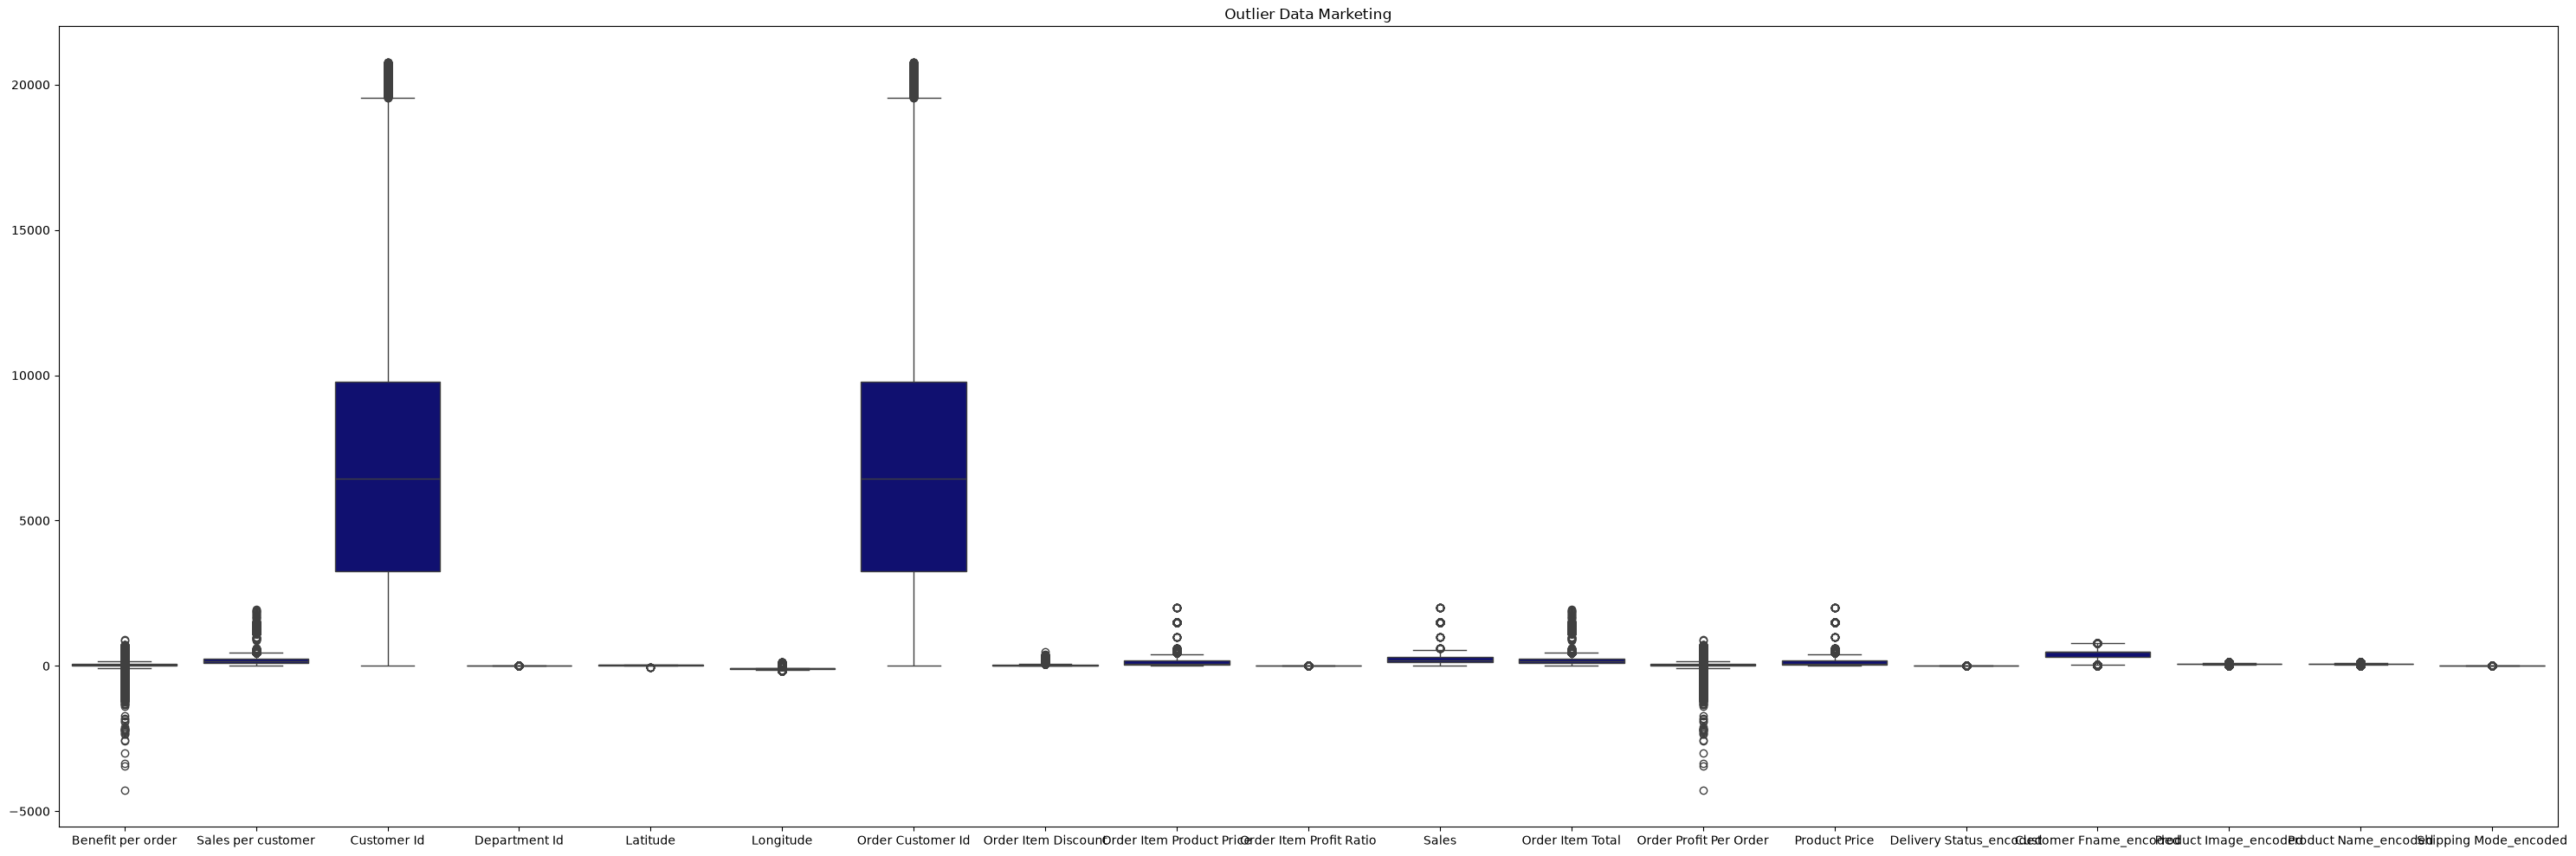

In [22]:
plt.figure(figsize=(30,10))
sns.boxplot(kolom_dengan_outlier, color="navy")
plt.title("Outlier Data Marketing")
plt.tight_layout()
plt.show()

### Distribusi Data (Dengan Uji D'Agostino-Pearson)

In [23]:
from scipy.stats import normaltest

In [24]:
summary_normal = []
alpha = 0.05
for i in kolom_numerik :
    statistic, p_value = normaltest(df_copy[i])

    if p_value < alpha:
        kesimpulan = "Tidak Normal (Tolak H0)"
    else:
        kesimpulan = "Normal (Gagal Tolak H0)"

    summary_normal.append({
        "Kolom": i,
        "Statistic": statistic,
        "p-value": p_value,
        "Kesimpulan": kesimpulan
    })

df_normal_summary = pd.DataFrame(summary_normal)
df_normal_summary = df_normal_summary.sort_values(by=("p-value"), ascending=False)
display(df_normal_summary)

,Kolom,Statistic,p-value,Kesimpulan
50,Product Name_encoded,1.155384e+03,1.292603e-251,Tidak Normal (Tolak H0)
49,Product Image_encoded,1.155384e+03,1.292603e-251,Tidak Normal (Tolak H0)
0,Days for shipping (real),4.354560e+04,0.000000e+00,Tidak Normal (Tolak H0)
3,Sales per customer,1.253346e+05,0.000000e+00,Tidak Normal (Tolak H0)
4,Late_delivery_risk,6.295992e+05,0.000000e+00,Tidak Normal (Tolak H0)
1,Days for shipment (scheduled),6.011899e+04,0.000000e+00,Tidak Normal (Tolak H0)
2,Benefit per order,1.866345e+05,0.000000e+00,Tidak Normal (Tolak H0)
8,Department Id,2.469703e+03,0.000000e+00,Tidak Normal (Tolak H0)
9,Latitude,9.564434e+05,0.000000e+00,Tidak Normal (Tolak H0)
10,Longitude,1.587206e+04,0.000000e+00,Tidak Normal (Tolak H0)


### Distribusi Data (Dengan Histogram)

In [25]:
'''Membuat Variabel Baru Untuk Mengambil Kolom Dengan Tipe Data Numerikal'''
numeric_df = df_copy.select_dtypes(include=["number"])

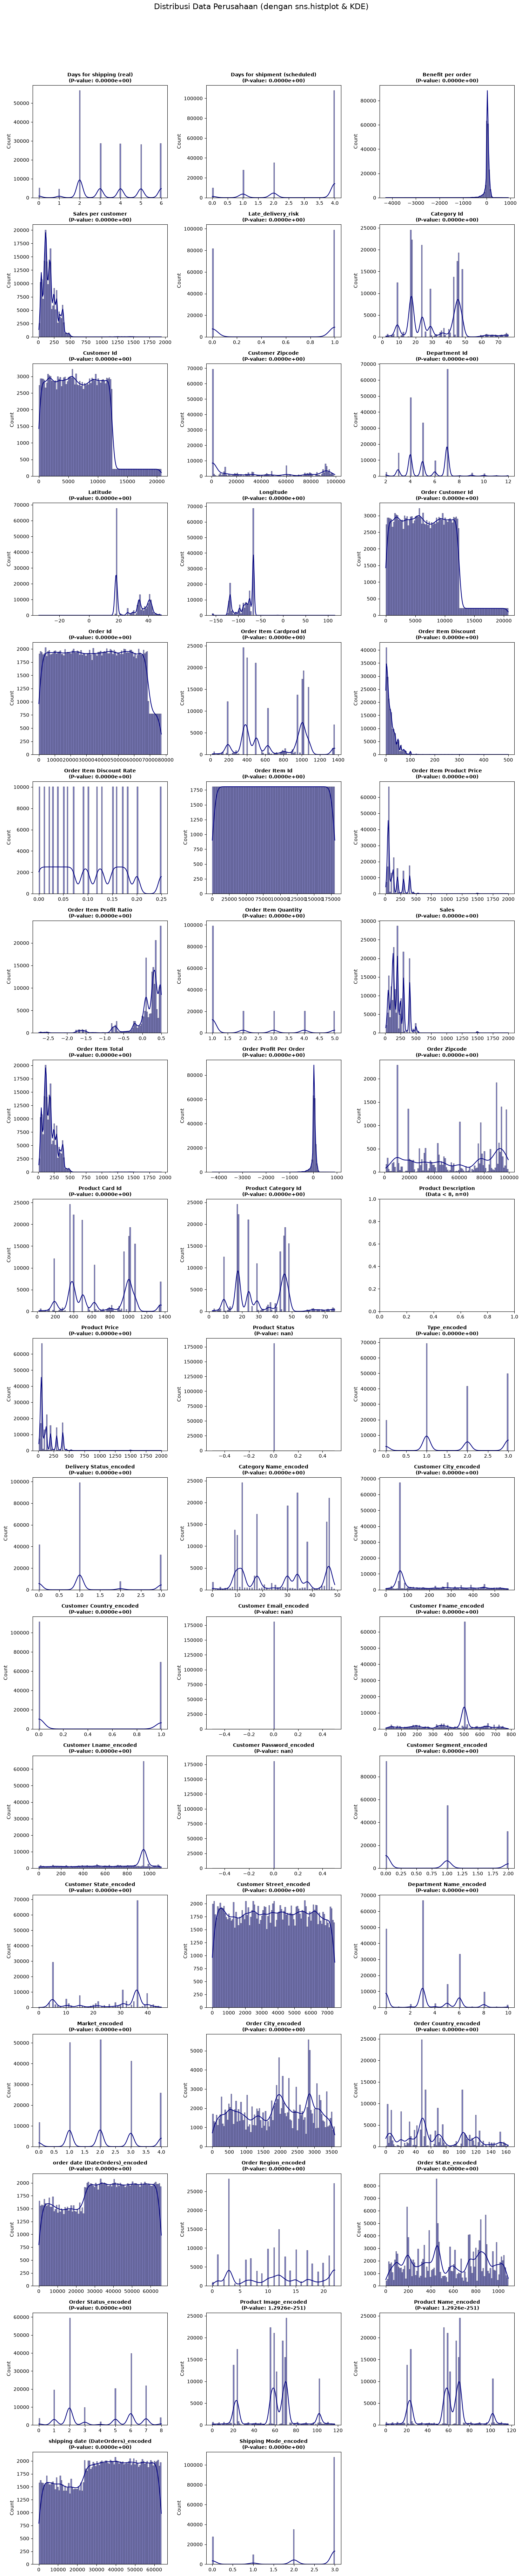

In [26]:
n_cols = 3
n_rows = int(np.ceil(len(kolom_numerik) / n_cols))

# 3. Membuat figure & axes
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()  # Meratakan array axes agar mudah di-loop

alpha = 0.05

# 4. Loop untuk plot sns.histplot dan menyisipkan P-value
for i, col in enumerate(kolom_numerik):
    # Hitung p-value (mengabaikan nilai NaN jika ada)
    data_bersih = df_copy[col].dropna()
    
    # PERBAIKAN: Cek apakah jumlah data mencukupi (minimal 8 data)
    if len(data_bersih) >= 8:
        statistic, p_value = normaltest(data_bersih)
        p_text = f"P-value: {p_value:.4e}" if p_value < 0.0001 else f"P-value: {p_value:.4f}"
        title_text = f"{col}\n({p_text})"
    else:
        title_text = f"{col}\n(Data < 8, n={len(data_bersih)})"
    
    # Menggunakan sns.histplot dengan garis KDE (Kurva Distribusi)
    # Gunakan penanganan jika data kosong sama sekali untuk menghindari error plot
    if len(data_bersih) > 0:
        sns.histplot(data_bersih, bins=100, color="navy", kde=True, ax=axes[i])
    
    # Menampilkan Nama Kolom dan P-value di judul subplot
    axes[i].set_title(title_text, fontsize=10, fontweight="bold")
    
    # Mengatur ulang label agar lebih rapi
    axes[i].set_xlabel("")
    axes[i].grid(False)

# 5. Sembunyikan subplot sisa yang tidak terpakai (jika ada kotak kosong)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Distribusi Data Perusahaan (dengan sns.histplot & KDE)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Heatmap

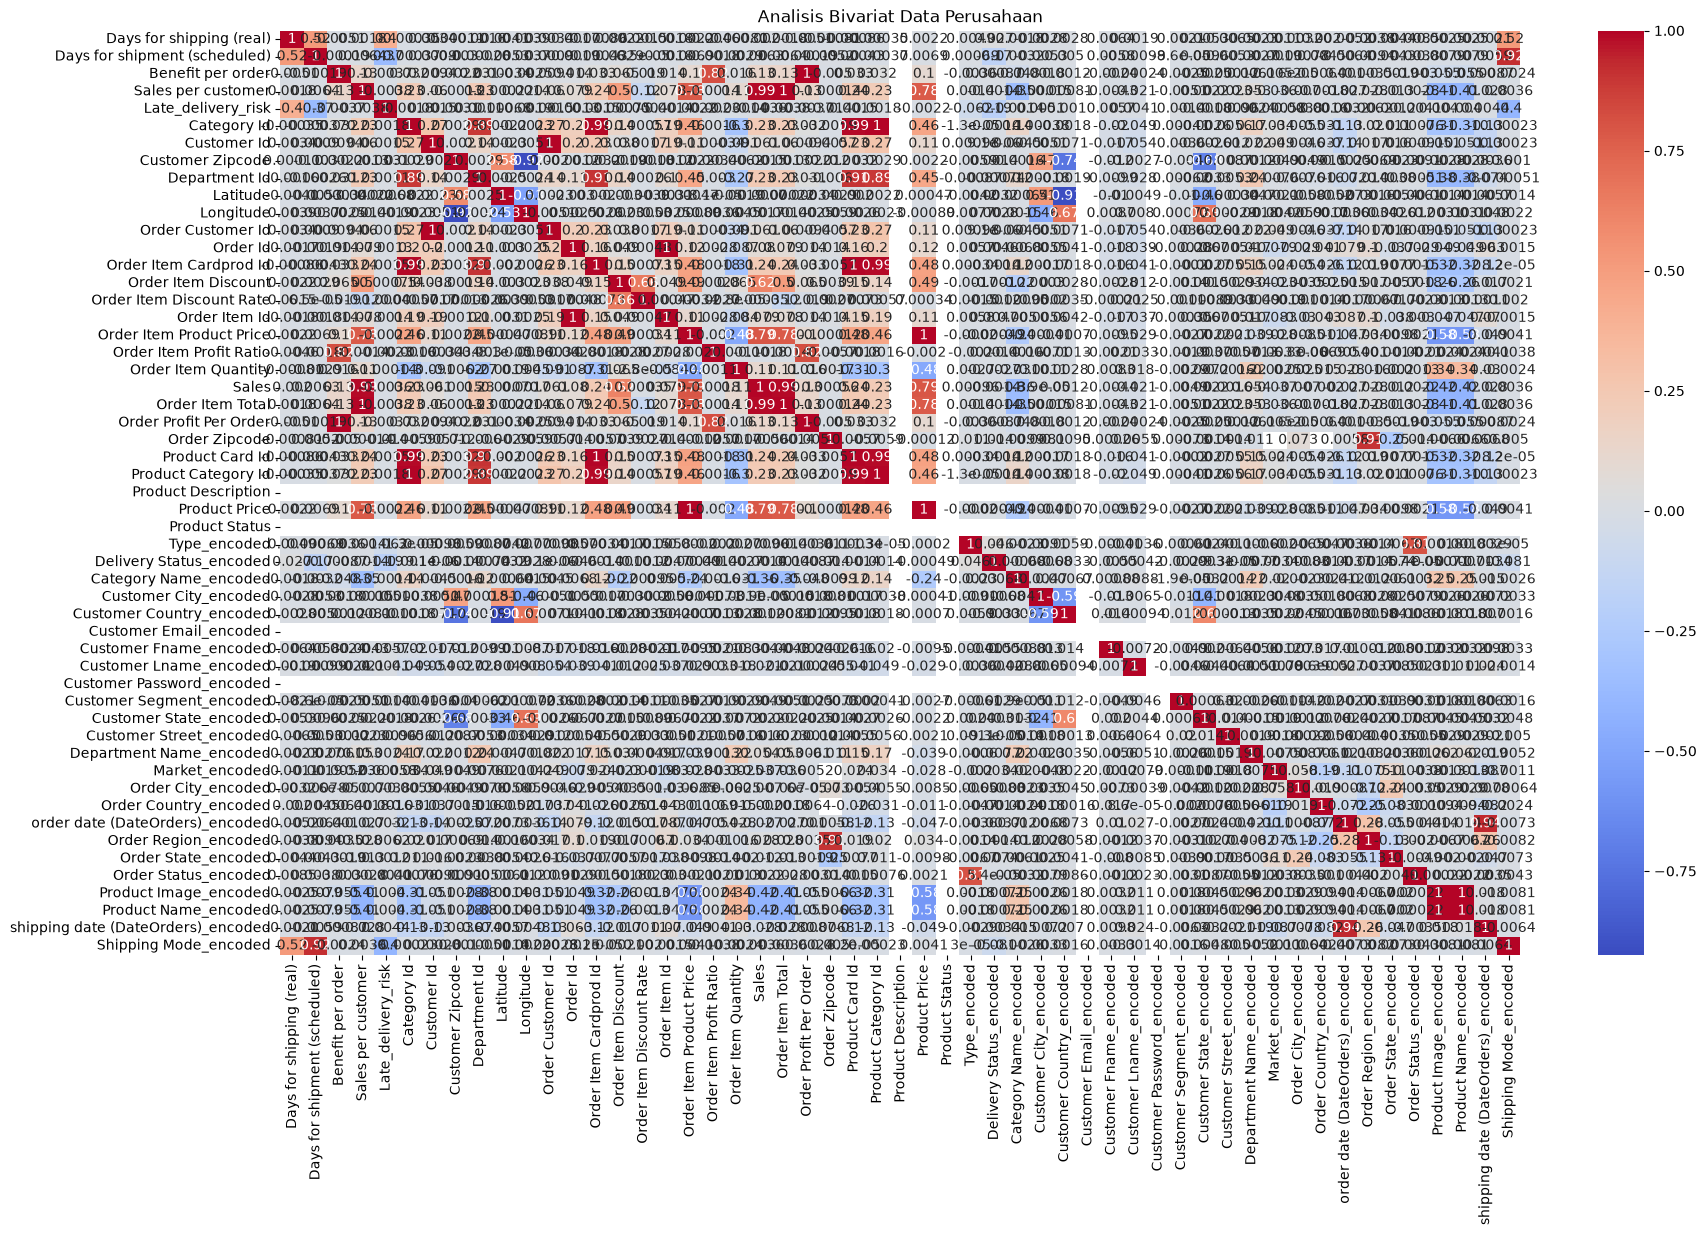

In [27]:
df_corr = numeric_df.corr()
plt.figure(figsize=(20, 12))
sns.heatmap(
    df_corr,
    annot=True,
    cmap="coolwarm"
)
plt.title("Analisis Bivariat Data Perusahaan")
plt.show()

### Heatmap Dengan Korelasi Tertinggi (Top 10)

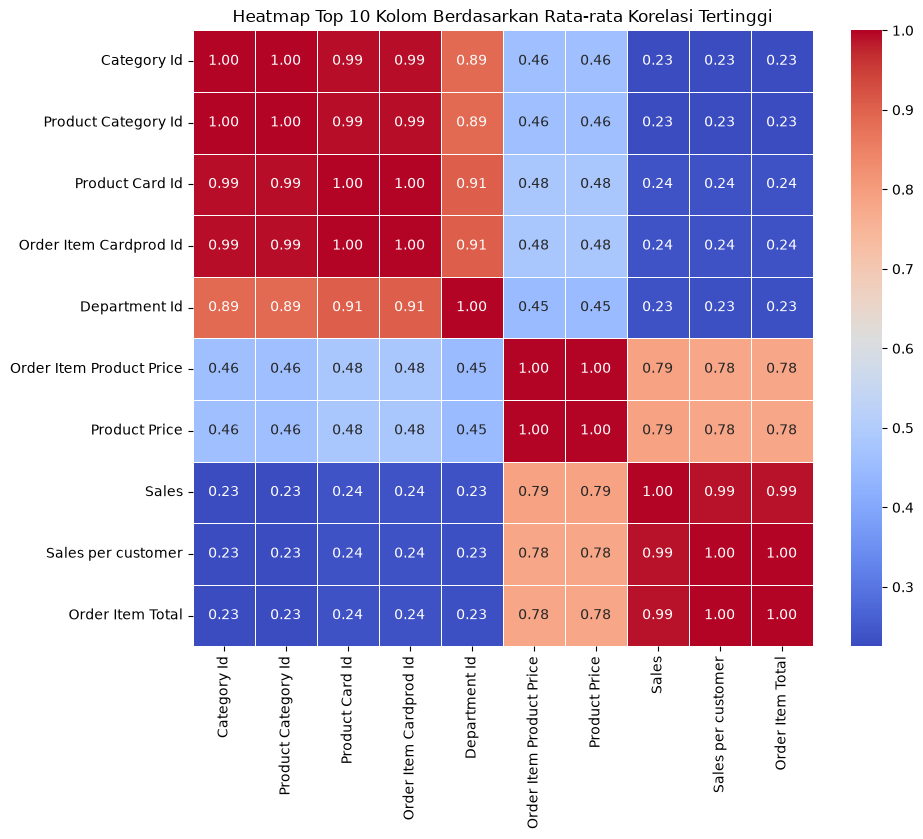

In [28]:
# Hitung matriks korelasi, lalu cari 10 kolom dengan rata-rata korelasi tertinggi
top_corr_cols = numeric_df.corr().mean().nlargest(10).index
corr_top = numeric_df[top_corr_cols].corr()

# Plot heatmap 10x10
plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Heatmap Top 10 Kolom Berdasarkan Rata-rata Korelasi Tertinggi")
plt.show()

### Heatmap Dengan Korelasi Terendah (Bottom 10)

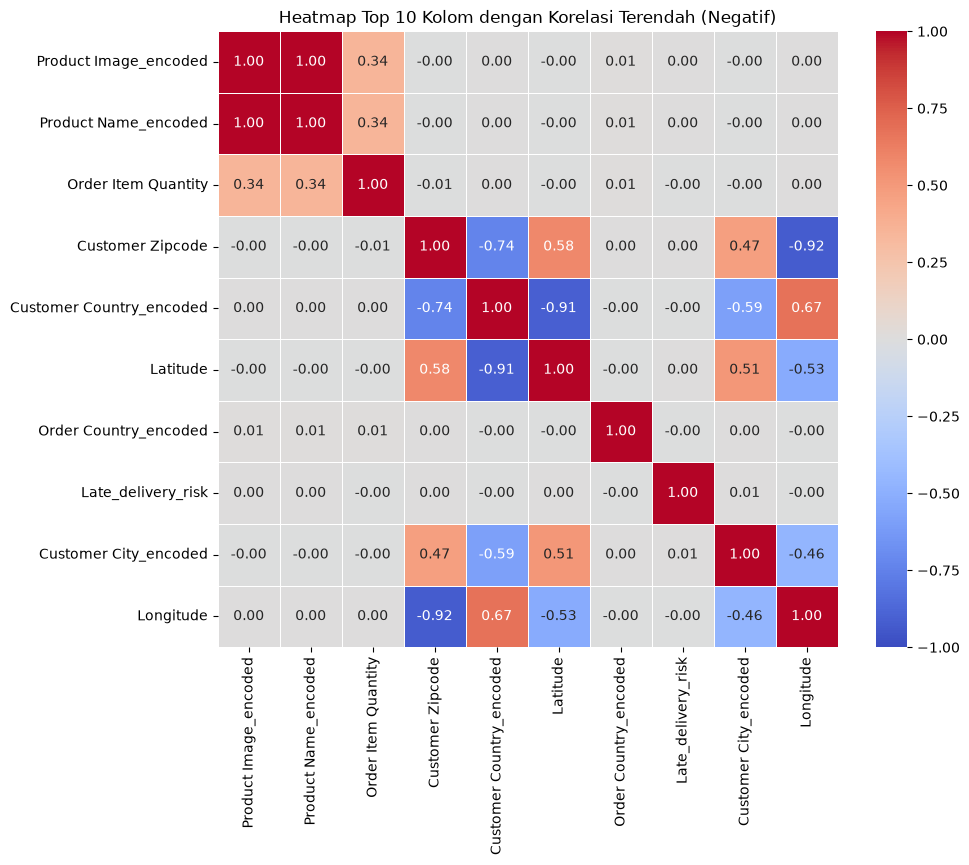

In [29]:
# Cari 10 kolom dengan rata-rata korelasi terendah (cenderung negatif)
lowest_corr_cols = numeric_df.corr().mean().nsmallest(10).index
corr_lowest = numeric_df[lowest_corr_cols].corr()

# Buat heatmap 10x10 khusus korelasi negatif/terendah
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_lowest, 
    annot=True, 
    cmap="coolwarm", 
    fmt=".2f", 
    linewidths=0.5, 
    vmin=-1,  # Mengunci batas bawah warna biru ke -1
    vmax=1    # Mengunci batas atas warna merah ke 1
)
plt.title("Heatmap Top 10 Kolom dengan Korelasi Terendah (Negatif)")
plt.show()

# Data Preparation

## Data Cleaning

### Penanganan Tipe Data

In [30]:
df_copy["Category Id"] = df_copy["Category Id"].astype("category")
df_copy["Customer Id"] = df_copy["Customer Id"].astype("category")
df_copy["Customer Zipcode"] = df_copy["Customer Zipcode"].astype("category")
df_copy["Department Id"] = df_copy["Department Id"].astype("category")
df_copy["Order Customer Id"] = df_copy["Order Customer Id"].astype("category")
df_copy["Order Id"] = df_copy["Order Id"].astype("category")
df_copy["Order Item Cardprod Id"] = df_copy["Order Item Cardprod Id"].astype("category")
df_copy["Order Item Id"] = df_copy["Order Item Id"].astype("category")
df_copy["Order Zipcode"] = df_copy["Order Zipcode"].astype("category")
df_copy["Product Card Id"] = df_copy["Product Card Id"].astype("category")
df_copy["Product Category Id"] = df_copy["Product Category Id"].astype("category")
df_copy["Product Description"] = df_copy["Product Description"].astype("str")
df_copy["order date (DateOrders)"] = pd.to_datetime(df_copy["order date (DateOrders)"], format="%m/%d/%Y %H:%M")
df_copy["shipping date (DateOrders)"] = pd.to_datetime(df_copy["shipping date (DateOrders)"], format="%m/%d/%Y %H:%M")

### Memeriksa Ulang Tipe Data

In [31]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 77 columns):
 #   Column                              Non-Null Count   Dtype         
---  ------                              --------------   -----         
 0   Type                                180519 non-null  str           
 1   Days for shipping (real)            180519 non-null  int64         
 2   Days for shipment (scheduled)       180519 non-null  int64         
 3   Benefit per order                   180519 non-null  float64       
 4   Sales per customer                  180519 non-null  float64       
 5   Delivery Status                     180519 non-null  str           
 6   Late_delivery_risk                  180519 non-null  int64         
 7   Category Id                         180519 non-null  category      
 8   Category Name                       180519 non-null  str           
 9   Customer City                       180519 non-null  str           
 10  Customer Country   

### Penanganan Missing Value

In [32]:
df_copy.drop(columns=["Product Description"], inplace=True)

## Feature Engineering (Membuat Kolom Baru)

In [33]:
df_copy["Hari_Telat"] = df_copy["Days for shipping (real)"] - df_copy["Days for shipment (scheduled)"]

In [34]:
def kategori_diskon(x):
    if x == 0:
        return "0%"
    elif 0 < x <= 0.05:
        return "1-5%"
    elif 0.05 < x <= 0.10:
        return "6-10%"
    elif 0.10 < x <= 0.15:
        return "11-15%"
    elif 0.15 < x <= 0.20:
        return "16-20%"
    else:
        return "21-25%"

df_copy["Kategori_Diskon"] = df_copy["Order Item Discount Rate"].apply(kategori_diskon)

In [35]:
def rugi(y) :
    if y < 0 :
        return 1
    else :
        return 0

df_copy["Rugi"] = df_copy["Benefit per order"].apply(rugi)

# EDA

## Heatmap

### Heatmap Dengan Korelasi Tertinggi (Top 10)

In [36]:
'''Membuat Variabel Baru Untuk Mengambil Kolom Dengan Tipe Data Numerikal'''
numeric_df_baru = df_copy.select_dtypes(include=["number"])

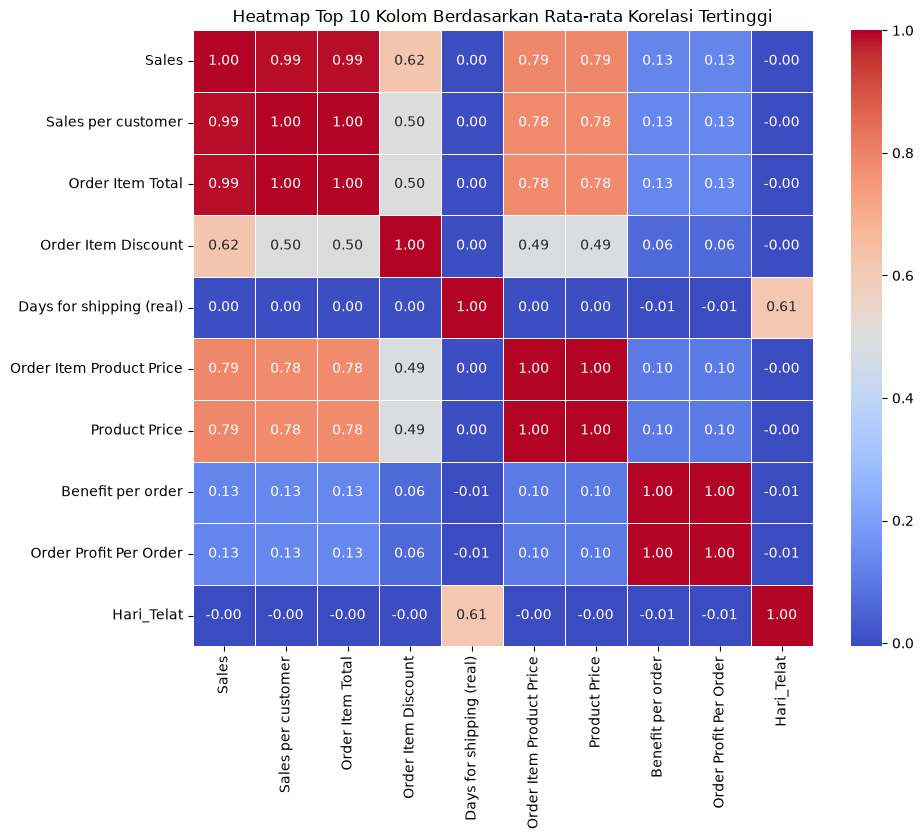

In [37]:
top_corr_cols = numeric_df_baru.corr().mean().nlargest(10).index
corr_top = numeric_df_baru[top_corr_cols].corr()

# Plot heatmap 10x10
plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Heatmap Top 10 Kolom Berdasarkan Rata-rata Korelasi Tertinggi")
plt.show()

### Heatmap Dengan Korelasi Terendah (Bottom 10)

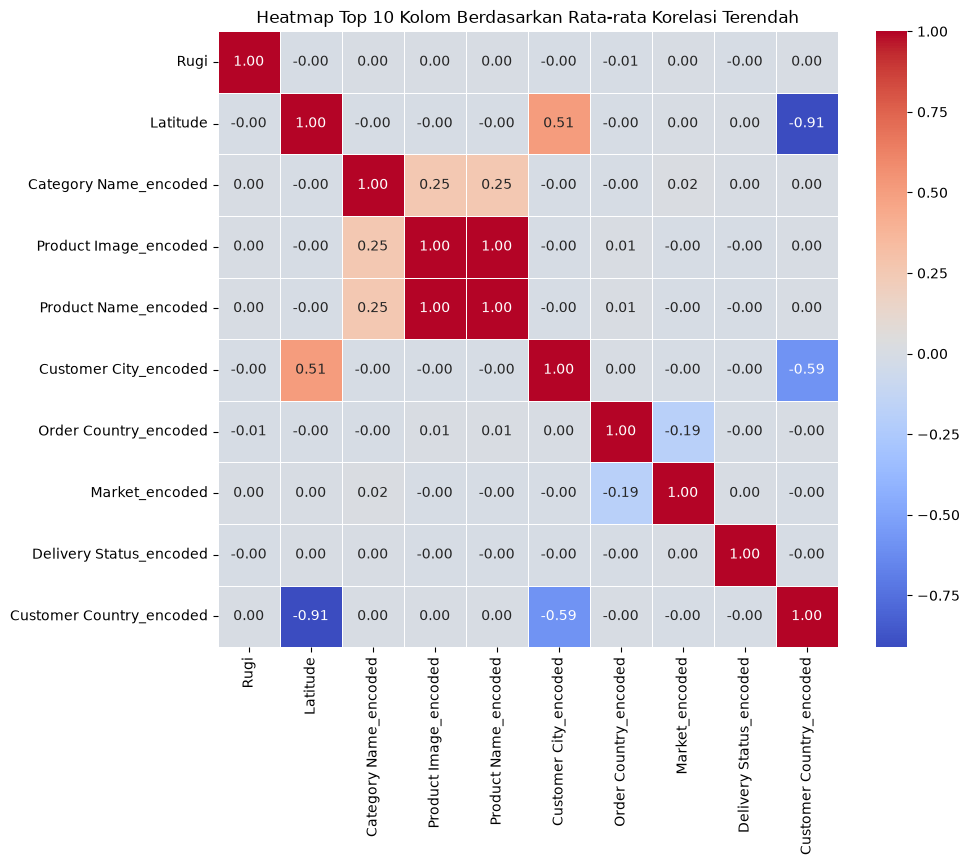

In [38]:
bottom_corr_cols = numeric_df_baru.corr().mean().nsmallest(10).index
corr_bottom = numeric_df_baru[bottom_corr_cols].corr()

# Plot heatmap 10x10
plt.figure(figsize=(10, 8))
sns.heatmap(corr_bottom, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Heatmap Top 10 Kolom Berdasarkan Rata-rata Korelasi Terendah")
plt.show()

### Heatmap Logistik

In [39]:
kolom_logistik = df_copy[[
    "Benefit per order", 
    "Sales", 
    "Order Item Discount", 
    "Order Item Discount Rate",  
    "Order Item Quantity", 
    "Product Price",
    "Rugi",
    "Shipping Mode_encoded",
    "Delivery Status_encoded", 
    "Hari_Telat",
    "Late_delivery_risk"
]]

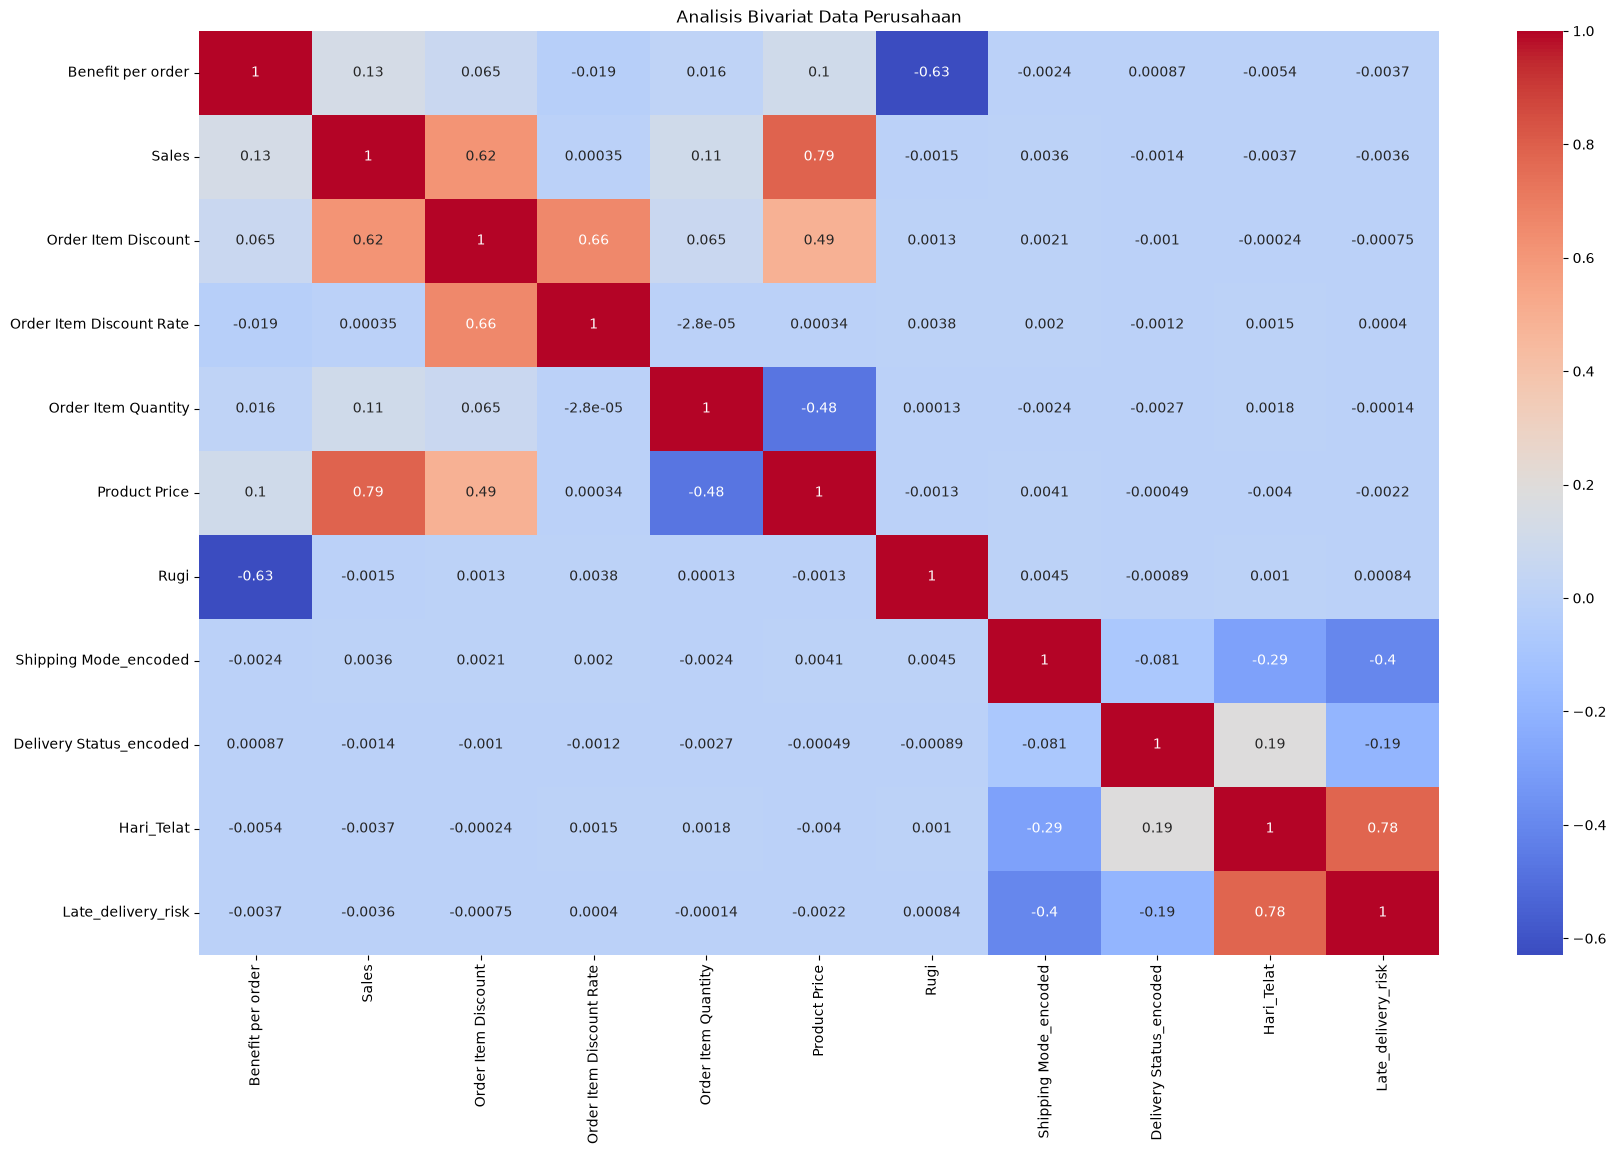

In [40]:
df_corr = kolom_logistik.corr()
plt.figure(figsize=(20, 12))
sns.heatmap(
    df_corr,
    annot=True,
    cmap="coolwarm"
)
plt.title("Analisis Bivariat Data Perusahaan")
plt.show()

### Heatmap Late delivery

In [41]:
'''Membuat Variabel Baru Untuk Mengambil Kolom Dengan Tipe Data Numerikal'''
numeric_df_baru_late = df_copy[df_copy["Delivery Status"] == "Late delivery"].select_dtypes(include=["number"])

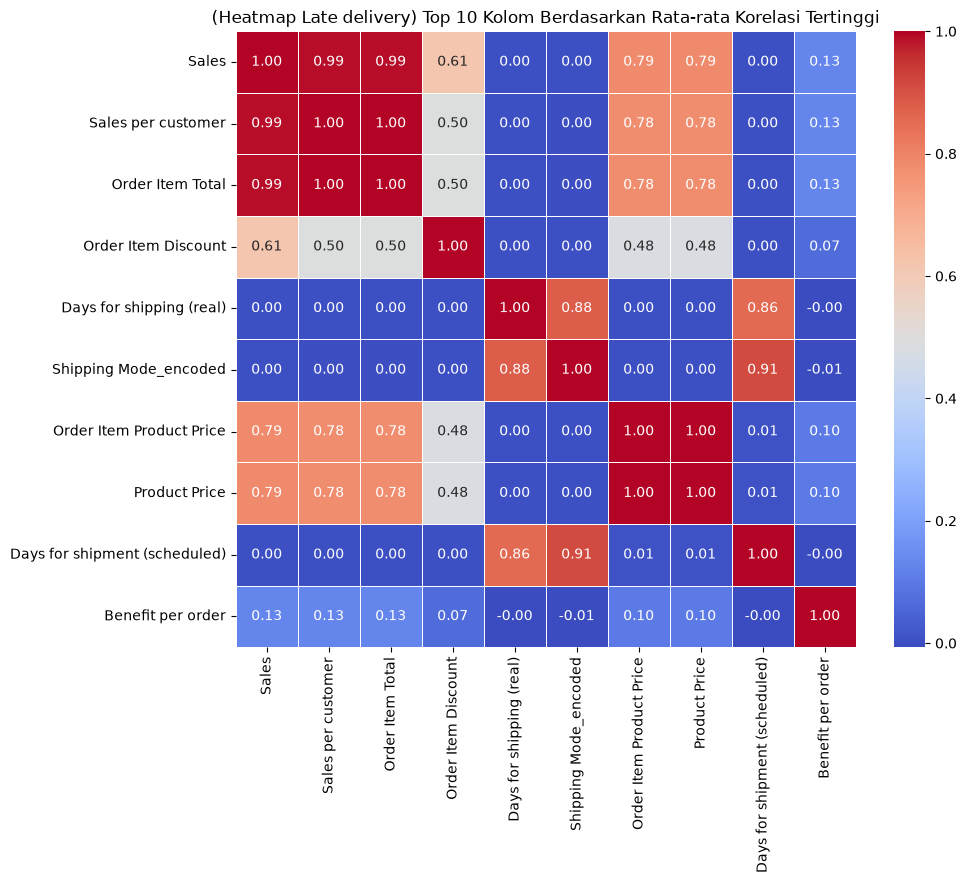

In [42]:
top_corr_cols = numeric_df_baru_late.corr().mean().nlargest(10).index
corr_top = numeric_df_baru_late[top_corr_cols].corr()

# Plot heatmap 10x10
plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("(Heatmap Late delivery) Top 10 Kolom Berdasarkan Rata-rata Korelasi Tertinggi")
plt.show()

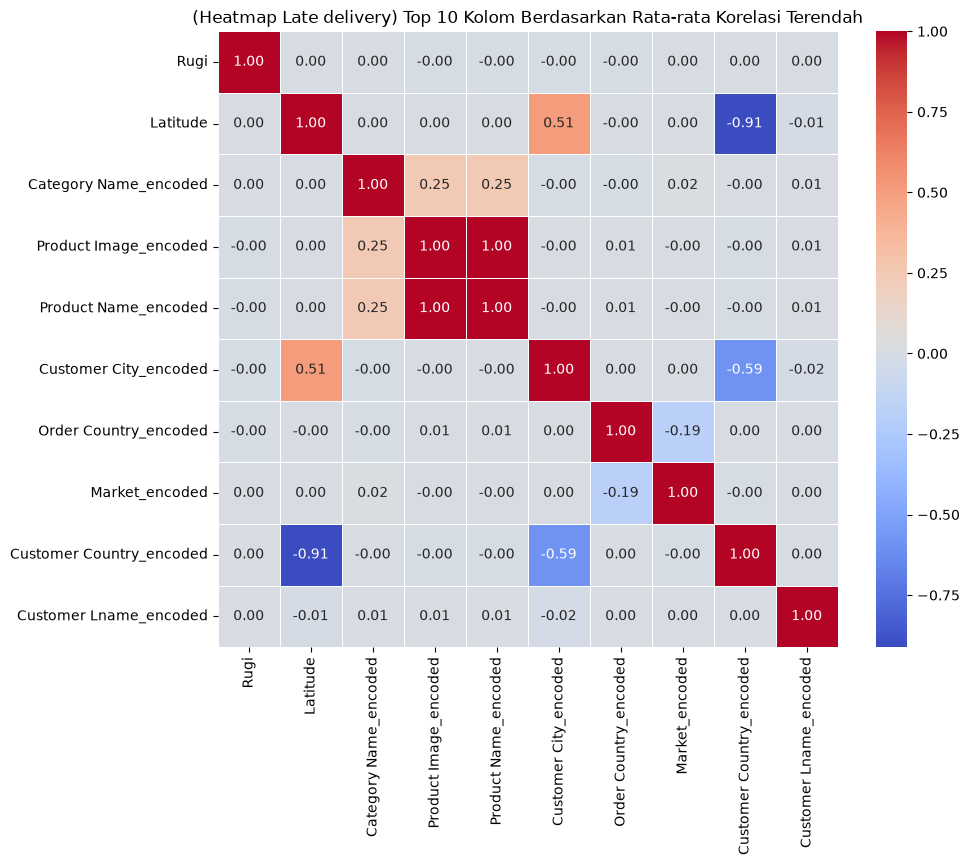

In [43]:
bottom_corr_cols = numeric_df_baru_late.corr().mean().nsmallest(10).index
corr_bottom = numeric_df_baru_late[bottom_corr_cols].corr()

# Plot heatmap 10x10
plt.figure(figsize=(10, 8))
sns.heatmap(corr_bottom, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("(Heatmap Late delivery) Top 10 Kolom Berdasarkan Rata-rata Korelasi Terendah")
plt.show()

## Analisis Univariat

### Jumlah Pengiriman Berdasarkan Status

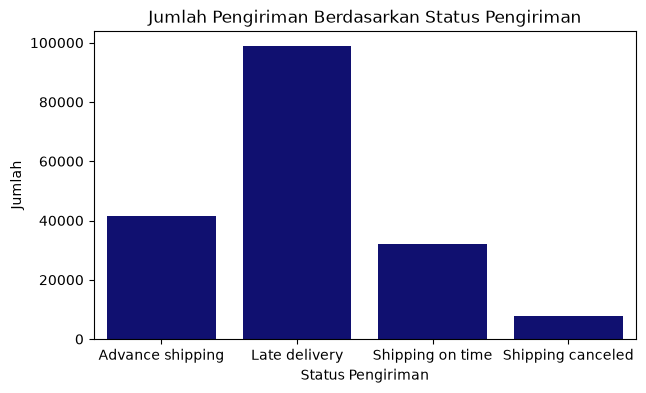

In [44]:
plt.figure(figsize=(7, 4))
sns.countplot(
    data=df_copy, 
    x="Delivery Status", 
    color="navy")
plt.title("Jumlah Pengiriman Berdasarkan Status Pengiriman")
plt.xlabel("Status Pengiriman")
plt.ylabel("Jumlah")
plt.show()

In [45]:
jumlah_telat = len(df_copy[df_copy["Delivery Status"]=="Late delivery"])
rata_rata_jumlah_telat = jumlah_telat/len(df_copy)*100

jumlah_batal = len(df_copy[df_copy["Delivery Status"]=="Shipping canceled"])
rata_rata_jumlah_batal = jumlah_batal/len(df_copy)*100

print(f"Jumlah Pengiriman Terlambat = {jumlah_telat}")
print(f"Persentase Pengiriman Terlambat = {round(rata_rata_jumlah_telat, 2)}%")
print("\n")
print(f"Jumlah Pengiriman Batal = {jumlah_batal}")
print(f"Persentase Pengiriman Batal = {round(rata_rata_jumlah_batal, 2)}%")

Jumlah Pengiriman Terlambat = 98977
Persentase Pengiriman Terlambat = 54.83%


Jumlah Pengiriman Batal = 7754
Persentase Pengiriman Batal = 4.3%


## Analisis Bivariat

### Jumlah Pengiriman Berdasarkan Jumlah Hari Telat dan Dengan Status Late delivery dan Shipping canceled

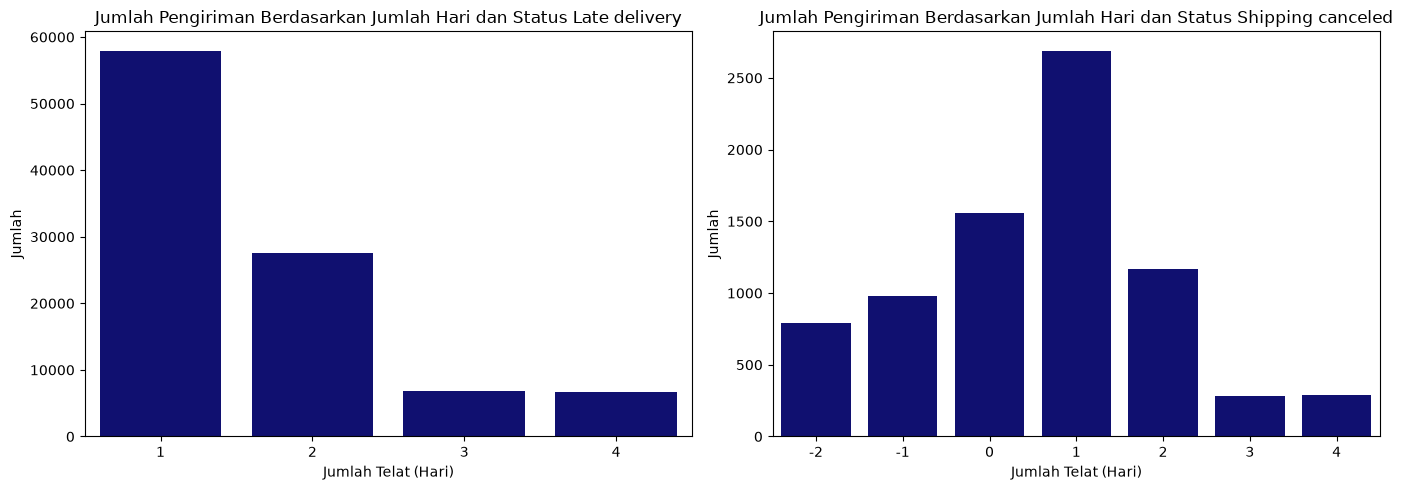

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Late delivery
sns.countplot(data=df_copy[df_copy["Delivery Status"] == "Late delivery"], x="Hari_Telat", color="navy", ax=axes[0])
axes[0].set_title("Jumlah Pengiriman Berdasarkan Jumlah Hari dan Status Late delivery")
axes[0].set_xlabel("Jumlah Telat (Hari)")
axes[0].set_ylabel("Jumlah")

# Plot Shipping canceled
sns.countplot(data=df_copy[df_copy["Delivery Status"] == "Shipping canceled"], x="Hari_Telat", color="navy", ax=axes[1])
axes[1].set_title("Jumlah Pengiriman Berdasarkan Jumlah Hari dan Status Shipping canceled")
axes[1].set_xlabel("Jumlah Telat (Hari)")
axes[1].set_ylabel("Jumlah")

plt.tight_layout()
plt.show()

### Status Order dan Tipe Pembayaran Yang Membatalkan Pengiriman

In [47]:
df_copy.groupby(["Delivery Status", "Type", "Order Status"]).agg(
    Jumlah_Status = ("Order Id", "count")
)

Jumlah_Status
Delivery Status   Type     Order Status                  
Advance shipping  CASH     CLOSED                    4809
                  DEBIT    COMPLETE                 14136
                           ON_HOLD                   2413
                  PAYMENT  PAYMENT_REVIEW             420
                           PENDING_PAYMENT           9588
                  TRANSFER PENDING                   4857
                           PROCESSING                5369
Late delivery     CASH     CLOSED                   11109
                  DEBIT    COMPLETE                 34199
                           ON_HOLD                   5450
                  PAYMENT  PAYMENT_REVIEW            1082
                           PENDING_PAYMENT          22922
                  TRANSFER PENDING                  11712
                           PROCESSING               12503
Shipping canceled TRANSFER CANCELED                  3692
                           SUSPECTED_FRAUD           4062
Shipping on time  CASH     CLOSED                    3698
                  DEBIT    COMPLETE                 11156
                           ON_HOLD                   1941
                  PAYMENT  PAYMENT_REVIEW             391
                           PENDING_PAYMENT           7322
                  TRANSFER PENDING                   3658
                           PROCESSING                4030

### Membandingkan Status Seluruh Pengiriman Tanpa Ada Kecurigaan Penipuan

In [48]:
# Pengiriman dengan kecurigaan penipuan tidak masuk ke dalam analisis
df_kirim = df_copy[df_copy["Order Status"] != "SUSPECTED_FRAUD"].copy()

# Membuat Kolom baru Telat (1 = telat dan 0 = tidak telat)
df_kirim["Telat"] = (df_kirim["Delivery Status"] == "Late delivery").astype(int)

jumlah_kirim = len(df_kirim)
jumlah_telat_kirim = df_kirim["Telat"].sum()
rata_telat = jumlah_telat_kirim / jumlah_kirim * 100

print(f"Jumlah pengiriman tanpa ada kecurigaan penipuan = {jumlah_kirim}")
print(f"Jumlah pengiriman terlambat = {jumlah_telat_kirim}")
print(f"Persentase pengiriman terlambat = {round(rata_telat, 2)}%")
print("\n")
print("Jumlah Pengiriman Berdasarkan Status :")
print(df_kirim["Delivery Status"].value_counts())
print("\n")
print("Persentase Pengiriman Berdasarkan Status :")
print((df_kirim["Delivery Status"].value_counts(normalize=True) * 100).round(2))

Jumlah pengiriman tanpa ada kecurigaan penipuan = 176457
Jumlah pengiriman terlambat = 98977
Persentase pengiriman terlambat = 56.09%


Jumlah Pengiriman Berdasarkan Status :
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     3692
Name: count, dtype: int64


Persentase Pengiriman Berdasarkan Status :
Delivery Status
Late delivery        56.09
Advance shipping     23.57
Shipping on time     18.25
Shipping canceled     2.09
Name: proportion, dtype: float64


### Persentase Telat Berdasarkan Wilayah, Segmen Pelanggan, Jenis Produk, dan Jenis Pengiriman

              Jumlah_Telat  Jumlah_Pengiriman  Persentase_Telat
Market                                                         
LATAM                28044              50412             55.63
Africa                6340              11377             55.73
USCA                 14138              25197             56.11
Pacific Asia         22712              40391             56.23
Europe               27743              49080             56.53
                  Jumlah_Telat  Jumlah_Pengiriman  Persentase_Telat
Customer Segment                                                   
Corporate                29982              53657             55.88
Consumer                 51248              91289             56.14
Home Office              17747              31511             56.32
                    Jumlah_Telat  Jumlah_Pengiriman  Persentase_Telat
Department Name                                                      
Discs Shop                  1103               1987             55.51
Fo

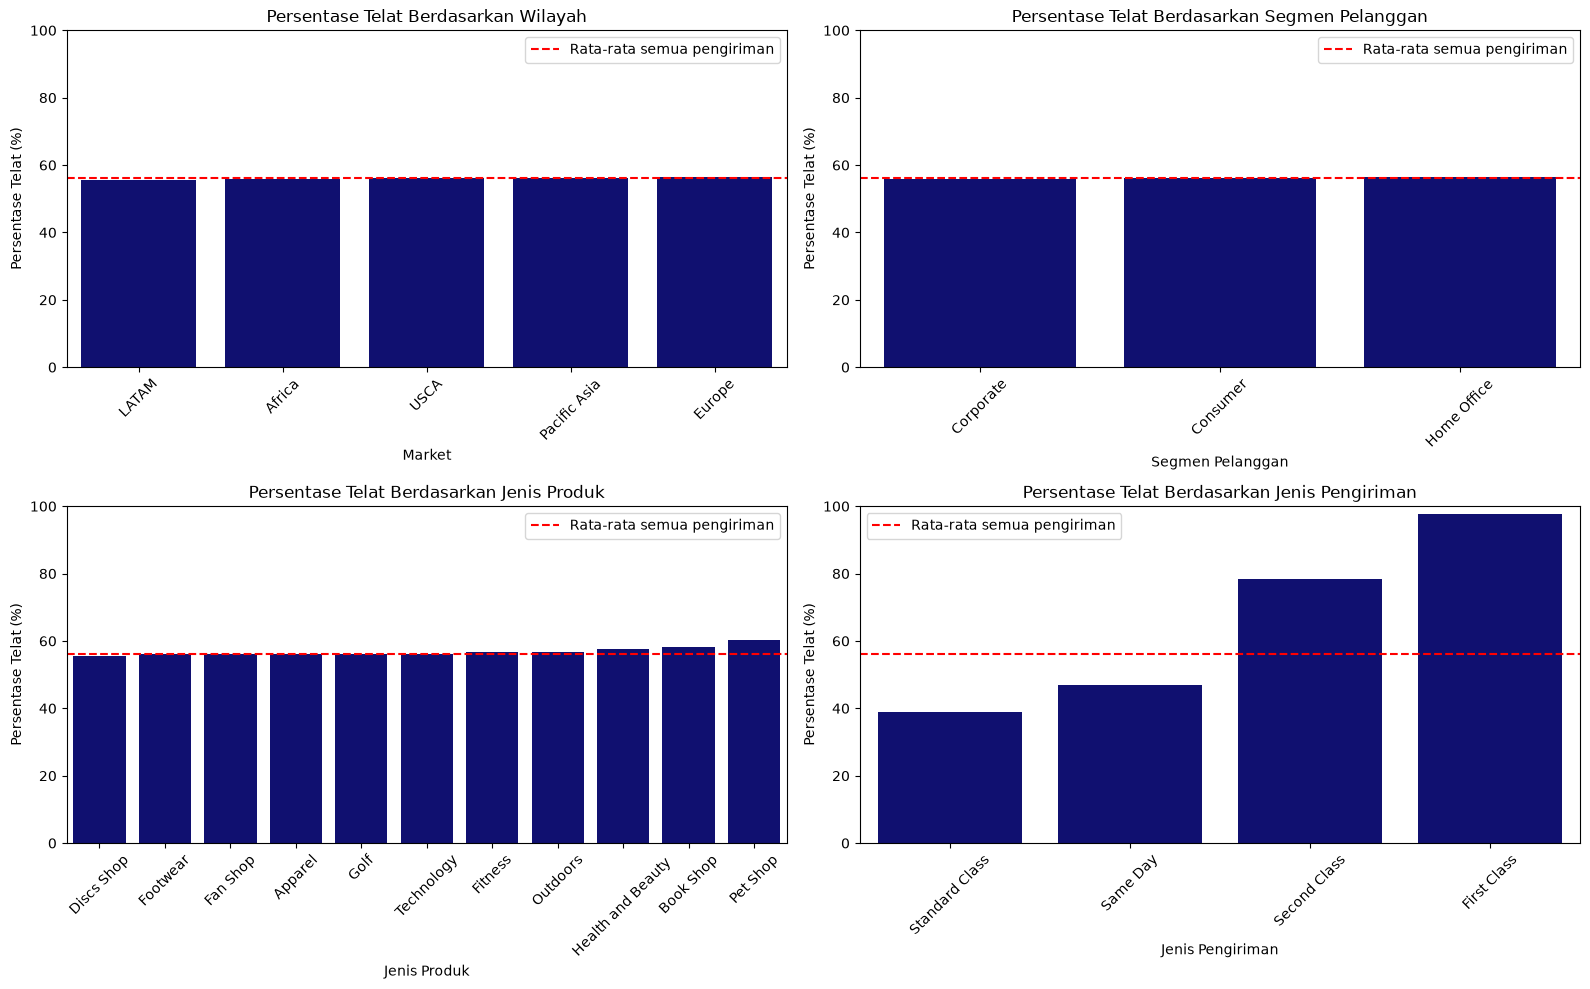

In [49]:
# 1. Menyusun Data
# A. Market
telat_market = df_kirim.groupby("Market").agg(
    Jumlah_Telat=("Telat", "sum"), Jumlah_Pengiriman=("Telat", "count")
)
telat_market["Persentase_Telat"] = (
    telat_market["Jumlah_Telat"] / telat_market["Jumlah_Pengiriman"] * 100
).round(2)
telat_market = telat_market.sort_values(by="Persentase_Telat")

# B. Customer Segment
telat_pelanggan = df_kirim.groupby("Customer Segment").agg(
    Jumlah_Telat=("Telat", "sum"), Jumlah_Pengiriman=("Telat", "count")
)
telat_pelanggan["Persentase_Telat"] = (
    telat_pelanggan["Jumlah_Telat"] / telat_pelanggan["Jumlah_Pengiriman"] * 100
).round(2)
telat_pelanggan = telat_pelanggan.sort_values(by="Persentase_Telat")

# C. Department Name (Jenis Produk)
telat_produk = df_kirim.groupby("Department Name").agg(
    Jumlah_Telat=("Telat", "sum"), Jumlah_Pengiriman=("Telat", "count")
)
telat_produk["Persentase_Telat"] = (
    telat_produk["Jumlah_Telat"] / telat_produk["Jumlah_Pengiriman"] * 100
).round(2)
telat_produk = telat_produk.sort_values(by="Persentase_Telat")

# D. Shipping Mode (Jenis Pengiriman)
telat_ship = df_kirim.groupby("Shipping Mode").agg(
    Jumlah_Telat=("Telat", "sum"), Jumlah_Pengiriman=("Telat", "count")
)
telat_ship["Persentase_Telat"] = (
    telat_ship["Jumlah_Telat"] / telat_ship["Jumlah_Pengiriman"] * 100
).round(2)
telat_ship = telat_ship.sort_values(by="Persentase_Telat")

print(telat_market)
print(telat_pelanggan)
print(telat_produk)
print(telat_ship)


# 2. Visualisasi Subplot (2 Baris, 2 Kolom)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# A. Plot Market (Baris 0, Kolom 0)
sns.barplot(
    x=telat_market.index,
    y=telat_market["Persentase_Telat"],
    color="navy",
    ax=axes[0, 0],
)
axes[0, 0].axhline(
    rata_telat, color="red", linestyle="--", label="Rata-rata semua pengiriman"
)
axes[0, 0].set_ylim(0, 100)
axes[0, 0].set_title("Persentase Telat Berdasarkan Wilayah")
axes[0, 0].set_xlabel("Market")
axes[0, 0].set_ylabel("Persentase Telat (%)")
axes[0, 0].legend()
axes[0, 0].tick_params(axis="x", rotation=45)

# B. Plot Customer Segment (Baris 0, Kolom 1)
sns.barplot(
    x=telat_pelanggan.index,
    y=telat_pelanggan["Persentase_Telat"],
    color="navy",
    ax=axes[0, 1],
)
axes[0, 1].axhline(
    rata_telat, color="red", linestyle="--", label="Rata-rata semua pengiriman"
)
axes[0, 1].set_ylim(0, 100)
axes[0, 1].set_title("Persentase Telat Berdasarkan Segmen Pelanggan")
axes[0, 1].set_xlabel("Segmen Pelanggan")
axes[0, 1].set_ylabel("Persentase Telat (%)")
axes[0, 1].legend()
axes[0, 1].tick_params(axis="x", rotation=45)

# C. Plot Department Name / Jenis Produk (Baris 1, Kolom 0)
sns.barplot(
    x=telat_produk.index,
    y=telat_produk["Persentase_Telat"],
    color="navy",
    ax=axes[1, 0],
)
axes[1, 0].axhline(
    rata_telat, color="red", linestyle="--", label="Rata-rata semua pengiriman"
)
axes[1, 0].set_ylim(0, 100)
axes[1, 0].set_title("Persentase Telat Berdasarkan Jenis Produk")
axes[1, 0].set_xlabel("Jenis Produk")
axes[1, 0].set_ylabel("Persentase Telat (%)")
axes[1, 0].legend()
axes[1, 0].tick_params(axis="x", rotation=45)

# D. Plot Shipping Mode / Jenis Pengiriman (Baris 1, Kolom 1)
sns.barplot(
    x=telat_ship.index,
    y=telat_ship["Persentase_Telat"],
    color="navy",
    ax=axes[1, 1],
)
axes[1, 1].axhline(
    rata_telat, color="red", linestyle="--", label="Rata-rata semua pengiriman"
)
axes[1, 1].set_ylim(0, 100)
axes[1, 1].set_title("Persentase Telat Berdasarkan Jenis Pengiriman")
axes[1, 1].set_xlabel("Jenis Pengiriman")
axes[1, 1].set_ylabel("Persentase Telat (%)")
axes[1, 1].legend()
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Rata Rata Hari Yang Dijanjikan Dengan Kenyataan Setiap Jenis Pengiriman Dengan Status Late Delivery

                Days for shipment (scheduled)  Days for shipping (real)
Shipping Mode                                                          
First Class                               1.0                      2.00
Same Day                                  0.0                      1.00
Second Class                              2.0                      4.50
Standard Class                            4.0                      5.51


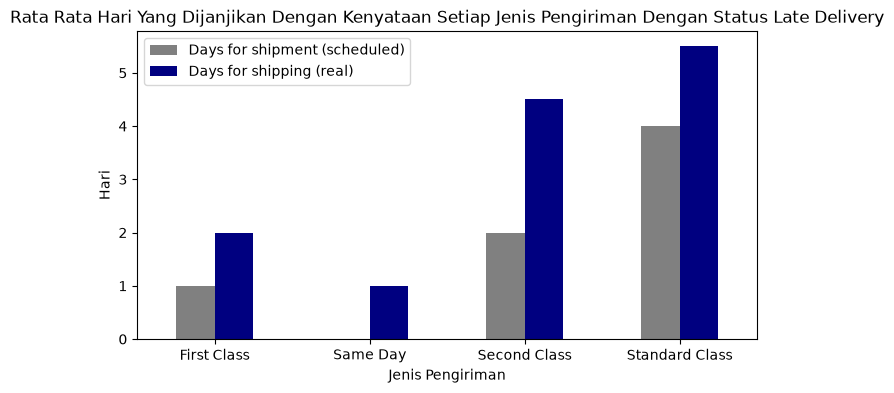

In [50]:
# Rata-rata hari terjadwal/janji dan hari kenyataan setiap jenis pengiriman
rata_hari = df_kirim[df_kirim["Delivery Status"] == "Late delivery"].groupby("Shipping Mode")[["Days for shipment (scheduled)", "Days for shipping (real)"]].mean().round(2)
print(rata_hari)

rata_hari.plot(kind="bar", figsize=(8, 4), color=["gray", "navy"])
plt.title("Rata Rata Hari Yang Dijanjikan Dengan Kenyataan Setiap Jenis Pengiriman Dengan Status Late Delivery")
plt.xlabel("Jenis Pengiriman")
plt.ylabel("Hari")
plt.xticks(rotation=0)
plt.show()

### Uji Statistik Chi-Square Kolom Telat dengan Jenis Pengiriman, Jenis Produk, Segmen Pelanggan, dan Wilayah

In [51]:
# Uji chi-square: apakah ada hubungan antara kolom ini dengan telat? (p-value < 0.05 artinya ada hubungan)
from scipy.stats import chi2_contingency

for kolom in ["Shipping Mode", "Department Name", "Customer Segment", "Market"]:
    tabel_silang = pd.crosstab(df_kirim[kolom], df_kirim["Telat"])
    chi2, p_value, dof, expected = chi2_contingency(tabel_silang)
    print(f"{kolom} dengan Telat -> p-value = {p_value:.4f}")
    if p_value < 0.05:
        print("Ada hubungan yang signifikan\n")
    else:
        print("Tidak ada bukti hubungan yang signifikan\n")

Shipping Mode dengan Telat -> p-value = 0.0000
Ada hubungan yang signifikan

Department Name dengan Telat -> p-value = 0.6903
Tidak ada bukti hubungan yang signifikan

Customer Segment dengan Telat -> p-value = 0.4169
Tidak ada bukti hubungan yang signifikan

Market dengan Telat -> p-value = 0.0595
Tidak ada bukti hubungan yang signifikan



## Analisis Multivariat

### Persentase Telat Pengiriman Berdasarkan Jenis Pengiriman dan Wilayah

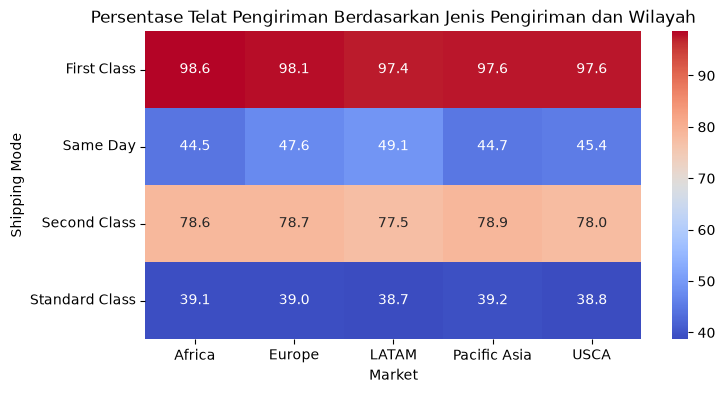

In [52]:
# Telat berdasarkan mode pengiriman x market
pivot_telat = df_kirim.pivot_table(index="Shipping Mode", columns="Market", values="Telat", aggfunc="mean") * 100

plt.figure(figsize=(8, 4))
sns.heatmap(pivot_telat, annot=True, fmt=".1f", cmap="coolwarm")
plt.title("Persentase Telat Pengiriman Berdasarkan Jenis Pengiriman dan Wilayah")
plt.show()

### Persentase Telat Pengiriman Dengan First Class (dengan warna) Berdasarkan Negara Toko dan Negara Pelanggan

In [53]:
kode_negara = {
    "Afganistán": "AFG", "Albania": "ALB", "Alemania": "DEU", "Angola": "AGO", "Arabia Saudí": "SAU",
    "Argelia": "DZA", "Argentina": "ARG", "Armenia": "ARM", "Australia": "AUS", "Austria": "AUT",
    "Azerbaiyán": "AZE", "Bangladés": "BGD", "Barbados": "BRB", "Baréin": "BHR", "Belice": "BLZ",
    "Benín": "BEN", "Bielorrusia": "BLR", "Bolivia": "BOL", "Bosnia y Herzegovina": "BIH", "Botsuana": "BWA",
    "Brasil": "BRA", "Bulgaria": "BGR", "Burkina Faso": "BFA", "Burundi": "BDI", "Bután": "BTN",
    "Bélgica": "BEL", "Camboya": "KHM", "Camerún": "CMR", "Canada": "CAN", "Chad": "TCD",
    "Chile": "CHL", "China": "CHN", "Chipre": "CYP", "Colombia": "COL", "Corea del Sur": "KOR",
    "Costa Rica": "CRI", "Costa de Marfil": "CIV", "Croacia": "HRV", "Cuba": "CUB", "Dinamarca": "DNK",
    "Ecuador": "ECU", "Egipto": "EGY", "El Salvador": "SLV", "Emiratos Árabes Unidos": "ARE", "Eritrea": "ERI",
    "Eslovaquia": "SVK", "Eslovenia": "SVN", "España": "ESP", "Estados Unidos": "USA", "Estonia": "EST",
    "Etiopía": "ETH", "Filipinas": "PHL", "Finlandia": "FIN", "Francia": "FRA", "Gabón": "GAB",
    "Georgia": "GEO", "Ghana": "GHA", "Grecia": "GRC", "Guadalupe": "GLP", "Guatemala": "GTM",
    "Guayana Francesa": "GUF", "Guinea": "GIN", "Guinea Ecuatorial": "GNQ", "Guinea-Bissau": "GNB", "Guyana": "GUY",
    "Haití": "HTI", "Honduras": "HND", "Hong Kong": "HKG", "Hungría": "HUN", "India": "IND",
    "Indonesia": "IDN", "Irak": "IRQ", "Irlanda": "IRL", "Irán": "IRN", "Israel": "ISR",
    "Italia": "ITA", "Jamaica": "JAM", "Japón": "JPN", "Jordania": "JOR", "Kazajistán": "KAZ",
    "Kenia": "KEN", "Kirguistán": "KGZ", "Kuwait": "KWT", "Laos": "LAO", "Lesoto": "LSO",
    "Liberia": "LBR", "Libia": "LBY", "Lituania": "LTU", "Luxemburgo": "LUX", "Líbano": "LBN",
    "Macedonia": "MKD", "Madagascar": "MDG", "Malasia": "MYS", "Mali": "MLI", "Marruecos": "MAR",
    "Martinica": "MTQ", "Mauritania": "MRT", "Moldavia": "MDA", "Mongolia": "MNG", "Montenegro": "MNE",
    "Mozambique": "MOZ", "Myanmar (Birmania)": "MMR", "México": "MEX", "Namibia": "NAM", "Nepal": "NPL",
    "Nicaragua": "NIC", "Nigeria": "NGA", "Noruega": "NOR", "Nueva Zelanda": "NZL", "Níger": "NER",
    "Omán": "OMN", "Pakistán": "PAK", "Panamá": "PAN", "Papúa Nueva Guinea": "PNG", "Paraguay": "PRY",
    "Países Bajos": "NLD", "Perú": "PER", "Polonia": "POL", "Portugal": "PRT", "Qatar": "QAT",
    "Reino Unido": "GBR", "República Centroafricana": "CAF", "República Checa": "CZE",
    "República Democrática del Congo": "COD", "República Dominicana": "DOM", "República de Gambia": "GMB",
    "República del Congo": "COG", "Ruanda": "RWA", "Rumania": "ROU", "Rusia": "RUS", "Senegal": "SEN",
    "Serbia": "SRB", "Sierra Leona": "SLE", "Singapur": "SGP", "Siria": "SYR", "Somalia": "SOM",
    "Sri Lanka": "LKA", "Suazilandia": "SWZ", "SudAfrica": "ZAF", "Sudán": "SDN", "Sudán del Sur": "SSD",
    "Suecia": "SWE", "Suiza": "CHE", "Surinam": "SUR", "Sáhara Occidental": "ESH", "Tailandia": "THA",
    "Taiwán": "TWN", "Tanzania": "TZA", "Tayikistán": "TJK", "Togo": "TGO", "Trinidad y Tobago": "TTO",
    "Turkmenistán": "TKM", "Turquía": "TUR", "Túnez": "TUN", "Ucrania": "UKR", "Uganda": "UGA",
    "Uruguay": "URY", "Uzbekistán": "UZB", "Venezuela": "VEN", "Vietnam": "VNM", "Yemen": "YEM",
    "Yibuti": "DJI", "Zambia": "ZMB", "Zimbabue": "ZWE"}

Negara tanpa kode : <ArrowStringArray>
[]
Length: 0, dtype: str


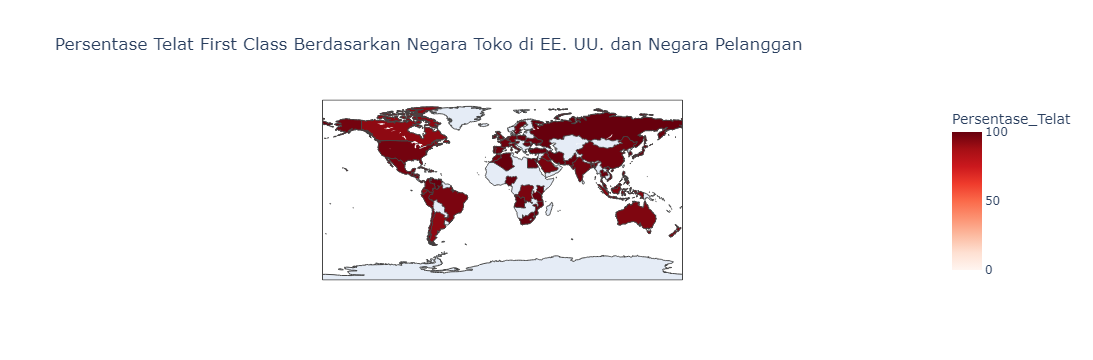

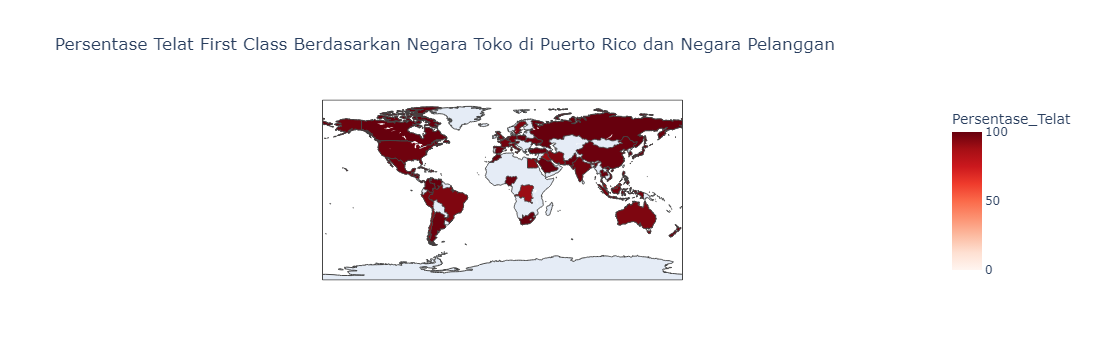

In [54]:
import plotly.express as px

# 1. Menambahkan kode negara tujuan
df_peta = df_kirim.copy()
df_peta["ISO3"] = df_peta["Order Country"].map(kode_negara)
print("Negara tanpa kode :", df_peta[df_peta["ISO3"].isnull()]["Order Country"].unique())

# 2. Pilih jenis pengiriman (ganti sesuai kebutuhan, misalnya "Second Class" atau "Standard Class")
jenis = "First Class"
data_jenis = df_peta[df_peta["Shipping Mode"] == jenis]

# 3. Hitung jumlah pengiriman dan persentase telat per negara asal pelanggan dan negara tujuan
tabel_peta = data_jenis.groupby(["Customer Country", "Order Country", "ISO3"]).agg(
    Jumlah_Pengiriman=("Telat", "count"),
    Persentase_Telat=("Telat", "mean")).reset_index()
tabel_peta["Persentase_Telat"] = tabel_peta["Persentase_Telat"] * 100

# 4. Negara dengan pengiriman terlalu sedikit tidak ditampilkan (persentasenya tidak stabil)
minimal_pengiriman = 30

# 5. Satu peta untuk setiap negara asal pelanggan
for negara_asal in tabel_peta["Customer Country"].unique():
    data_negara = tabel_peta[(tabel_peta["Customer Country"] == negara_asal) &
                             (tabel_peta["Jumlah_Pengiriman"] >= minimal_pengiriman)]
    fig = px.choropleth(
        data_negara,
        locations="ISO3",
        color="Persentase_Telat",
        hover_name="Order Country",
        hover_data={"Jumlah_Pengiriman": True, "ISO3": False},
        color_continuous_scale="Reds",
        range_color=(0, 100),
        title=f"Persentase Telat {jenis} Berdasarkan Negara Toko di {negara_asal} dan Negara Pelanggan")
    fig.show()

### Persentase Telat Pengiriman Dengan Second Class (dengan warna) Berdasarkan Negara Toko dan Negara Pelanggan

Negara tanpa kode : <ArrowStringArray>
[]
Length: 0, dtype: str


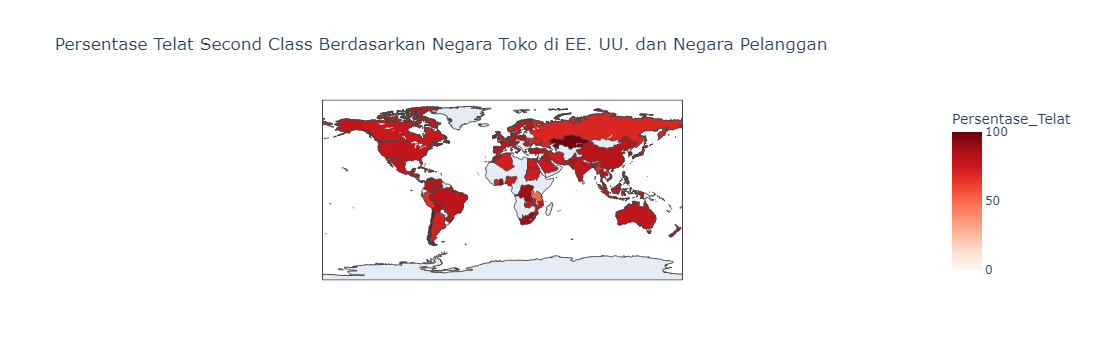

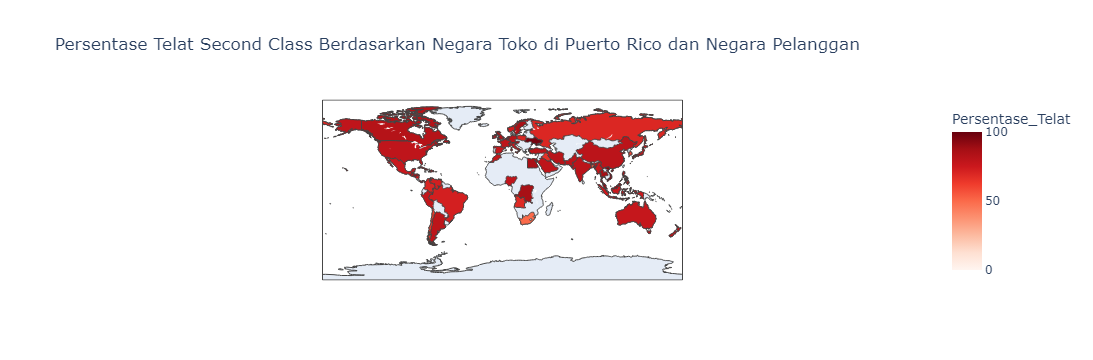

In [55]:
# 1. Menambahkan kode negara tujuan
df_peta = df_kirim.copy()
df_peta["ISO3"] = df_peta["Order Country"].map(kode_negara)
print("Negara tanpa kode :", df_peta[df_peta["ISO3"].isnull()]["Order Country"].unique())

# 2. Pilih jenis pengiriman (ganti sesuai kebutuhan, misalnya "Second Class" atau "Standard Class")
jenis = "Second Class"
data_jenis = df_peta[df_peta["Shipping Mode"] == jenis]

# 3. Hitung jumlah pengiriman dan persentase telat per negara asal pelanggan dan negara tujuan
tabel_peta = data_jenis.groupby(["Customer Country", "Order Country", "ISO3"]).agg(
    Jumlah_Pengiriman=("Telat", "count"),
    Persentase_Telat=("Telat", "mean")).reset_index()
tabel_peta["Persentase_Telat"] = tabel_peta["Persentase_Telat"] * 100

# 4. Negara dengan pengiriman terlalu sedikit tidak ditampilkan (persentasenya tidak stabil)
minimal_pengiriman = 30

# 5. Satu peta untuk setiap negara asal pelanggan
for negara_asal in tabel_peta["Customer Country"].unique():
    data_negara = tabel_peta[(tabel_peta["Customer Country"] == negara_asal) &
                             (tabel_peta["Jumlah_Pengiriman"] >= minimal_pengiriman)]
    fig = px.choropleth(
        data_negara,
        locations="ISO3",
        color="Persentase_Telat",
        hover_name="Order Country",
        hover_data={"Jumlah_Pengiriman": True, "ISO3": False},
        color_continuous_scale="Reds",
        range_color=(0, 100),
        title=f"Persentase Telat {jenis} Berdasarkan Negara Toko di {negara_asal} dan Negara Pelanggan")
    fig.show()

### Jumlah Telat Pengiriman dan Jumlah Hari Telat Berdasarkan Jenis Pengiriman

Hari_Telat          1      2     3     4
Shipping Mode                           
First Class     26513      0     0     0
Same Day         4454      0     0     0
Second Class     6759   6759  6772  6697
Standard Class  20231  20792     0     0


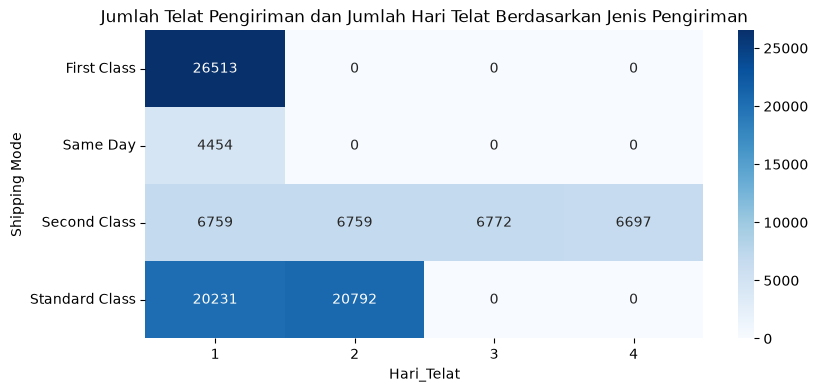

In [56]:
# Jumlah pengiriman berdasarkan mode x Hari_Telat (negatif = lebih cepat, 0 = tepat waktu, positif = telat)
tabel_hari = pd.crosstab(df_kirim[df_kirim["Telat"] == 1]["Shipping Mode"], df_kirim["Hari_Telat"])
print(tabel_hari)

plt.figure(figsize=(9, 4))
sns.heatmap(tabel_hari, annot=True, fmt="d", cmap="Blues")
plt.title("Jumlah Telat Pengiriman dan Jumlah Hari Telat Berdasarkan Jenis Pengiriman")
plt.show()

### Persentase Telat Pengiriman Berdasarkan Jenis Pengiriman Dan Jam Pemesanan

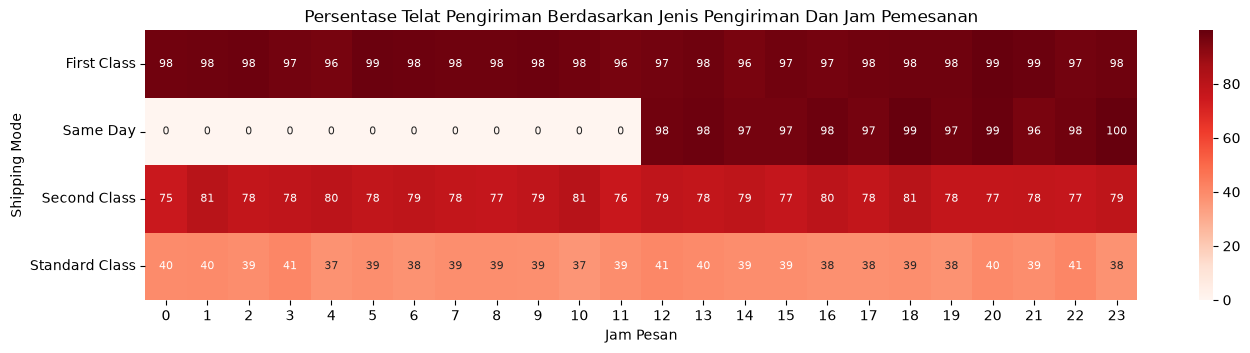

Days for shipping (real)     0     1
Waktu_Pesan                         
Jam 12 atau lebih            0  4555
Sebelum jam 12            4963     0


Waktu_Pesan
Jam 12 atau lebih    97.78
Sebelum jam 12        0.00
Name: Telat, dtype: float64


In [57]:
# Apakah jam pesan memengaruhi telat? (khusus dicek per mode pengiriman)
df_kirim["Jam_Order"] = df_kirim["order date (DateOrders)"].dt.hour

telat_jam = df_kirim.pivot_table(index="Shipping Mode", columns="Jam_Order", values="Telat", aggfunc="mean") * 100

plt.figure(figsize=(16, 3.5))
sns.heatmap(telat_jam, annot=True, fmt=".0f", cmap="Reds", annot_kws={"size": 8})
plt.title("Persentase Telat Pengiriman Berdasarkan Jenis Pengiriman Dan Jam Pemesanan")
plt.xlabel("Jam Pesan")
plt.show()

# Khusus Same Day: lama kirim aktual sebelum dan sesudah jam 12
df_sameday = df_kirim[df_kirim["Shipping Mode"] == "Same Day"].copy()
df_sameday["Waktu_Pesan"] = np.where(df_sameday["Jam_Order"] < 12, "Sebelum jam 12", "Jam 12 atau lebih")
print(pd.crosstab(df_sameday["Waktu_Pesan"], df_sameday["Days for shipping (real)"]))
print("\n")
print((df_sameday.groupby("Waktu_Pesan")["Telat"].mean() * 100).round(2))

## Simulasi Janji Baru

### Persentase Telat Jika Janji Lama Kirim Diubah

                Janji 1 hari  Janji 2 hari  Janji 3 hari  Janji 4 hari  \
Shipping Mode                                                            
First Class            100.0           0.0           0.0           0.0   
Same Day                 0.0           0.0           0.0           0.0   
Second Class           100.0          79.7          59.7          39.8   
Standard Class         100.0          79.8          59.7          39.8   

                Janji 5 hari  Janji 6 hari  
Shipping Mode                               
First Class              0.0           0.0  
Same Day                 0.0           0.0  
Second Class            19.8           0.0  
Standard Class          20.2           0.0  


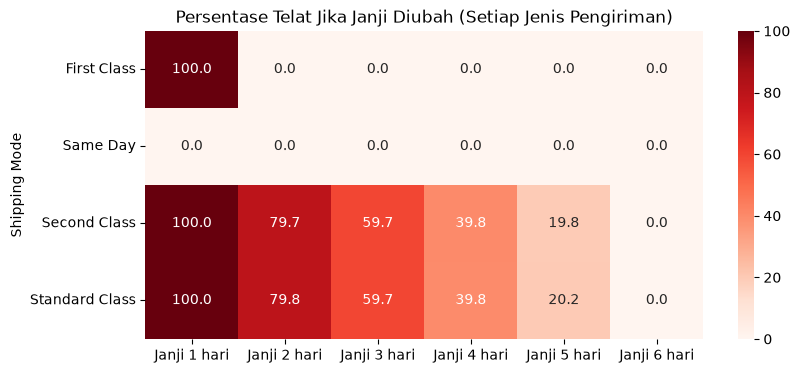

In [58]:
# Simulasi jika janji lama kirim diubah menjadi janji baru kirim
tabel_simulasi = pd.DataFrame()
for hari_janji in [1, 2, 3, 4, 5, 6]:
    telat_simulasi = df_kirim["Days for shipping (real)"] > hari_janji
    tabel_simulasi[f"Janji {hari_janji} hari"] = telat_simulasi.groupby(df_kirim["Shipping Mode"]).mean() * 100

print(tabel_simulasi.round(1))

plt.figure(figsize=(9, 4))
sns.heatmap(tabel_simulasi, annot=True, fmt=".1f", cmap="Reds")
plt.title("Persentase Telat Jika Janji Diubah (Setiap Jenis Pengiriman)")
plt.show()

## Insight EDA

# Ekstrak Data

In [59]:
df_clean = df_copy.copy()

In [60]:
df_clean.head(2)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode,Type_encoded,Delivery Status_encoded,Category Name_encoded,Customer City_encoded,Customer Country_encoded,Customer Email_encoded,Customer Fname_encoded,Customer Lname_encoded,Customer Password_encoded,Customer Segment_encoded,Customer State_encoded,Customer Street_encoded,Department Name_encoded,Market_encoded,Order City_encoded,Order Country_encoded,order date (DateOrders)_encoded,Order Region_encoded,Order State_encoded,Order Status_encoded,Product Image_encoded,Product Name_encoded,shipping date (DateOrders)_encoded,Shipping Mode_encoded,Hari_Telat,Kategori_Diskon,Rugi
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,2018-01-31 22:56:00,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class,1,0,40,66,1,0,109,482,0,0,36,3683,4,3,331,70,5961,15,475,2,78,78,27149,3,-1,1-5%,0
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,2018-01-13 12:27:00,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class,3,1,40,66,1,0,311,615,0,0,36,1400,4,3,391,69,1147,13,841,5,78,78,2209,3,1,6-10%,1


In [61]:
df_clean.drop(columns=[
    "Type_encoded", 
    "Delivery Status_encoded",
    "Category Name_encoded",
    "Customer City_encoded",
    "Customer Country_encoded",
    "Customer Email_encoded",
    "Customer Fname_encoded",
    "Customer Lname_encoded",
    "Customer Password_encoded",
    "Customer Segment_encoded",
    "Customer State_encoded",
    "Customer Street_encoded",
    "Department Name_encoded",
    "Market_encoded",
    "Order City_encoded",
    "Order Country_encoded",
    "order date (DateOrders)_encoded",
    "Order Region_encoded",
    "Order State_encoded",
    "Order Status_encoded",
    "Product Image_encoded",
    "Product Name_encoded",
    "shipping date (DateOrders)_encoded",
    "Shipping Mode_encoded",
    "Customer Password"
], inplace=True)

In [62]:
df_clean["Order Country ISO3"] = df_clean["Order Country"].map(kode_negara)

In [63]:
df_clean.to_csv("DataCoSupplyChainDataset_Clean.csv", index=False, sep=';', encoding='utf-8')